In [36]:
#Imports
import cv2 #cv2: librería que permite abrir videos, extraer frames y procesar imagenes.
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from scipy.stats import skew
from skimage.feature import graycoprops
import pandas as pd
from IPython.display import display 
from skimage.filters import sobel
from skimage.segmentation import watershed


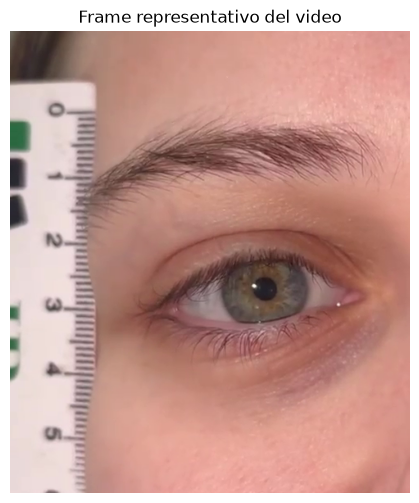

Se cargo la ROI guardada


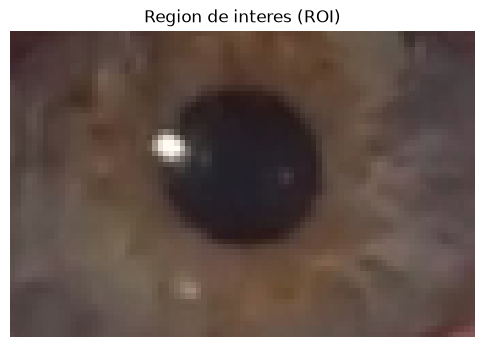

Dimensiones de la ROI:
Ancho: 85 pixeles
Alto: 56 pixeles
Cantidad de canales: 3
Profundidad de bits por canal: 8
Profundidad total por pixel: 24 bits


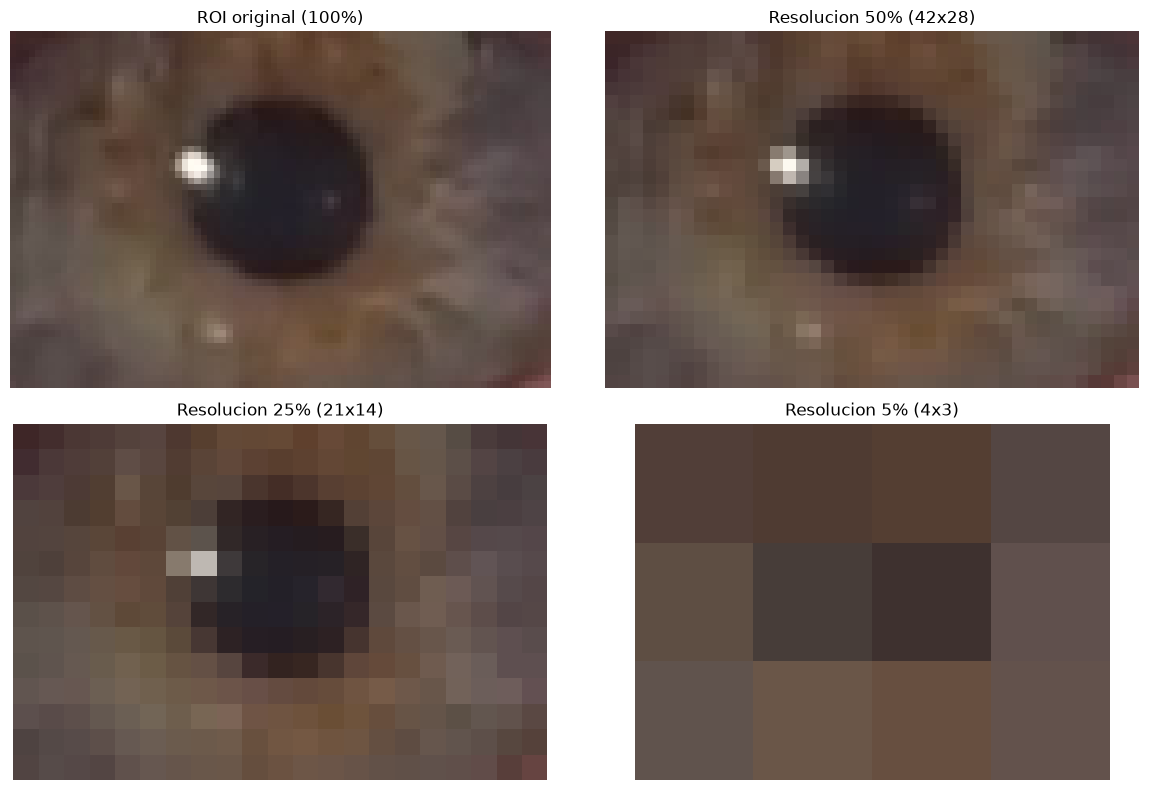

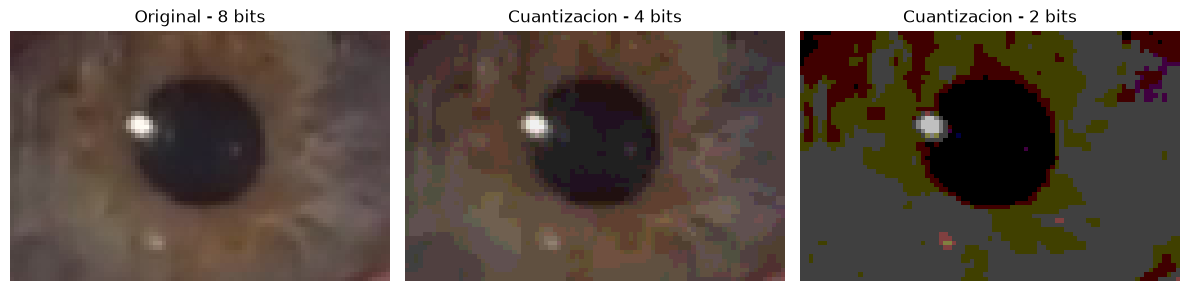

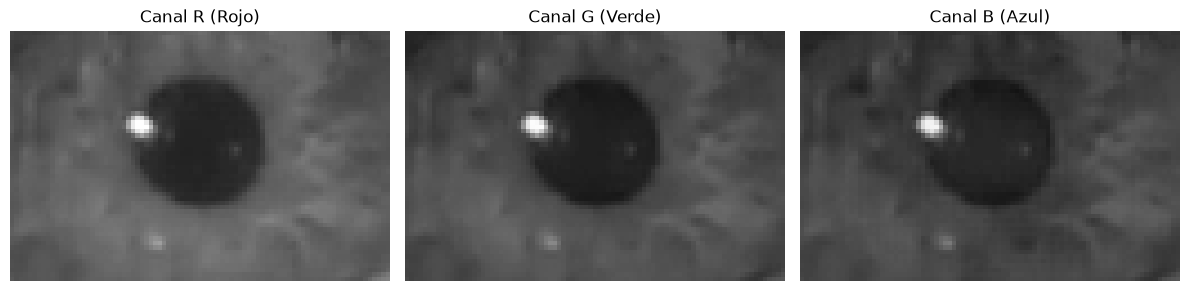

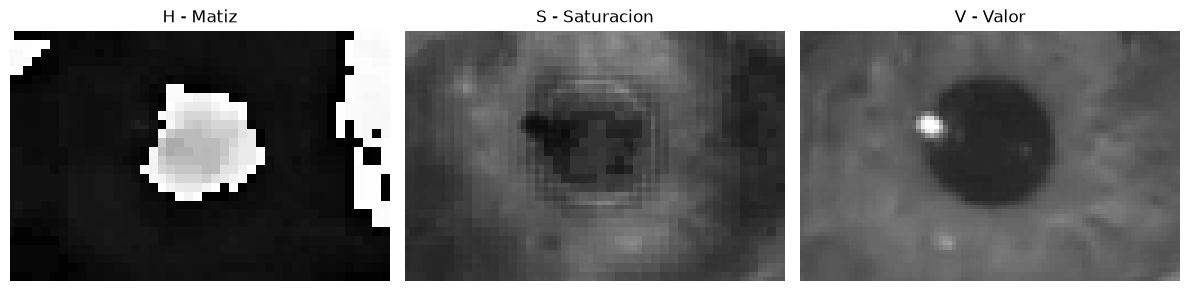

In [37]:
#Módulo 1:  

# Ruta del video
CARPETA_PROYECTO = Path.cwd()
VIDEO_PATH = CARPETA_PROYECTO / "datos" / "Videos_ojo" / "video1.mov"
VIDEO_PATH = CARPETA_PROYECTO / "datos" / "Videos_ojo" / "video1.mov"
#__file__ es la ubicacion del archivo que estamos trabajando, en este caso main.py

# Abrir el video
video = cv2.VideoCapture(str(VIDEO_PATH))

#Si el video no se puede abrir, tira error
if not video.isOpened():
    raise ValueError("No se pudo abrir el video")

#1.1.1

# Obtener la cantidad de frames
total_frames = int(video.get(cv2.CAP_PROP_FRAME_COUNT))


# Seleccionar un frame en un instante determinado
segundo = 6

fps = video.get(cv2.CAP_PROP_FPS)
frame_num = int(segundo * fps)

video.set(cv2.CAP_PROP_POS_FRAMES, frame_num)

# Extraer el frame
ret, frame = video.read()
video.release()

if not ret:
    raise ValueError("No se pudo extraer el frame")

# Convertir de BGR (en lo que trabaja opencvs) a RGB para visualizarlo
frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

# Mostrar el frame
plt.figure(figsize=(8, 6))
plt.imshow(frame_rgb)
plt.title("Frame representativo del video")
plt.axis("off")
plt.show()

# Ruta donde se guarda la ROI
ROI_PATH = CARPETA_PROYECTO / "imagenes" / "roi.png"

# Verificar si ya existe una ROI guardada
if ROI_PATH.exists():

    # Si existe, cargarla directamente
    roi = cv2.imread(str(ROI_PATH))
    print("Se cargo la ROI guardada")

else:

    # Si no existe, seleccionar una nueva ROI
    x, y, w, h = cv2.selectROI("Seleccionar ROI", frame, False)
    cv2.destroyAllWindows()

    if w == 0 or h == 0:
        raise ValueError("No se selecciono una ROI")

    roi = frame[y:y+h, x:x+w]

    # Guardar la ROI seleccionada como png en mi compu
    cv2.imwrite(str(ROI_PATH), roi)

# Crear carpeta IMAGENES, donde vamos a guardar el frame y el roi
CARPETA_IMAGENES = CARPETA_PROYECTO / "imagenes"
CARPETA_IMAGENES.mkdir(exist_ok=True)

# Guardar frame completo como png en mi compu
cv2.imwrite(str(CARPETA_IMAGENES / "frame.png"), frame)


# Visualizar ROI
roi_rgb = cv2.cvtColor(roi, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6, 6))
plt.imshow(roi_rgb)
plt.title("Region de interes (ROI)")
plt.axis("off")
plt.show()


# 1.1.2 Dimensiones y profundidad de bits

alto, ancho, canales = roi.shape

# Cantidad de bits por canal
bits = roi.dtype.itemsize * 8

print("Dimensiones de la ROI:")
print(f"Ancho: {ancho} pixeles")
print(f"Alto: {alto} pixeles")
print(f"Cantidad de canales: {canales}")
print(f"Profundidad de bits por canal: {bits}")
print(f"Profundidad total por pixel: {bits * canales} bits")


# 1.1.3 Resolucion espacial: submuestreo

escalas = [0.50, 0.25, 0.05]

plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(roi_rgb)
plt.title("ROI original (100%)")
plt.axis("off")

for i, escala in enumerate(escalas):
    nuevo_ancho = max(1, round(ancho * escala))
    nuevo_alto = max(1, round(alto * escala))

    roi_reducida = cv2.resize(
        roi_rgb,
        (nuevo_ancho, nuevo_alto),
        interpolation=cv2.INTER_AREA
    )

    plt.subplot(2, 2, i + 2)
    plt.imshow(roi_reducida, interpolation="nearest")
    plt.title(f"Resolucion {int(escala * 100)}% ({nuevo_ancho}x{nuevo_alto})")
    plt.axis("off")

plt.tight_layout()
plt.show()

# 1.1.4 Cuantizacion (profundidad de bits)

# Funcion para reducir la cantidad de niveles de intensidad
def cuantizar(imagen, bits):
    niveles = 2 ** bits
    paso = 256 // niveles

    imagen_cuantizada = (imagen // paso) * paso

    return imagen_cuantizada.astype("uint8")


# Cuantizacion de la ROI a 4 y 2 bits por canal
roi_4bits = cuantizar(roi_rgb, 4)
roi_2bits = cuantizar(roi_rgb, 2)

# Visualizacion comparativa
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(roi_rgb)
plt.title("Original - 8 bits")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(roi_4bits)
plt.title("Cuantizacion - 4 bits")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(roi_2bits)
plt.title("Cuantizacion - 2 bits")
plt.axis("off")

plt.tight_layout()
plt.show()


# 1.1.5 Espacios de color

# A. Separacion de los canales RGB

# Separar la ROI en sus tres canales de color
R, G, B = cv2.split(roi_rgb)

# Visualizar cada canal en escala de grises
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(R, cmap="gray", vmin=0, vmax=255)
plt.title("Canal R (Rojo)")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(G, cmap="gray", vmin=0, vmax=255)
plt.title("Canal G (Verde)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(B, cmap="gray", vmin=0, vmax=255)
plt.title("Canal B (Azul)")
plt.axis("off")

plt.tight_layout()
plt.show()


# B. Conversion del espacio RGB a HSV

# Convertir la ROI de RGB a HSV
roi_hsv = cv2.cvtColor(roi_rgb, cv2.COLOR_RGB2HSV)

# Separar las componentes HSV
H, S, V = cv2.split(roi_hsv)

# Visualizar cada componente en escala de grises
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(H, cmap="gray", vmin=0, vmax=179)
plt.title("H - Matiz")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(S, cmap="gray", vmin=0, vmax=255)
plt.title("S - Saturacion")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(V, cmap="gray", vmin=0, vmax=255)
plt.title("V - Valor")
plt.axis("off")

plt.tight_layout()
plt.show()


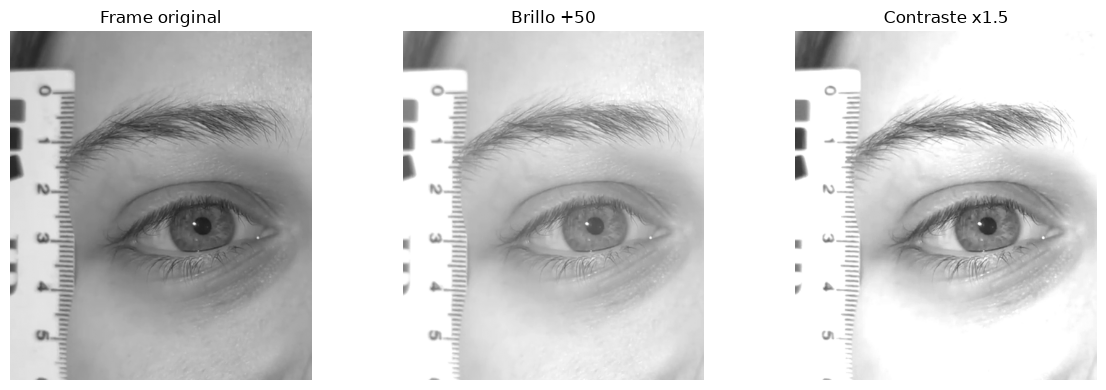

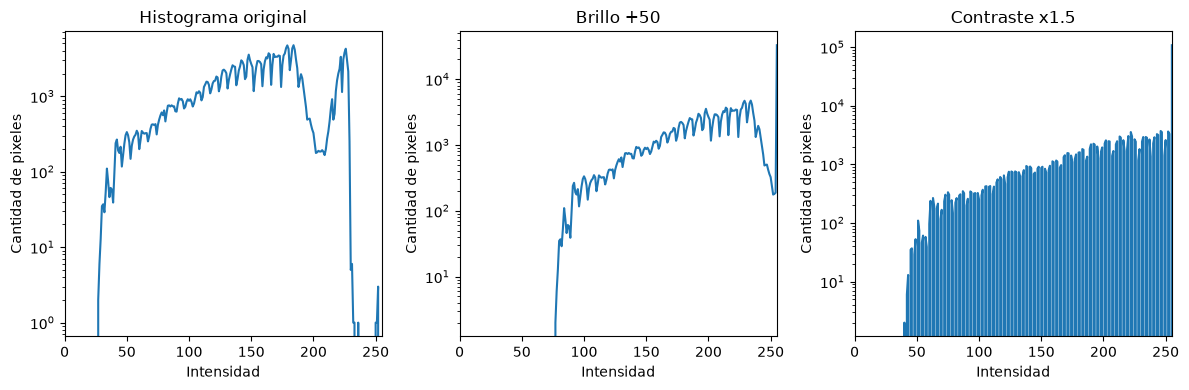

f1 = 34.0
f2 = 98.0


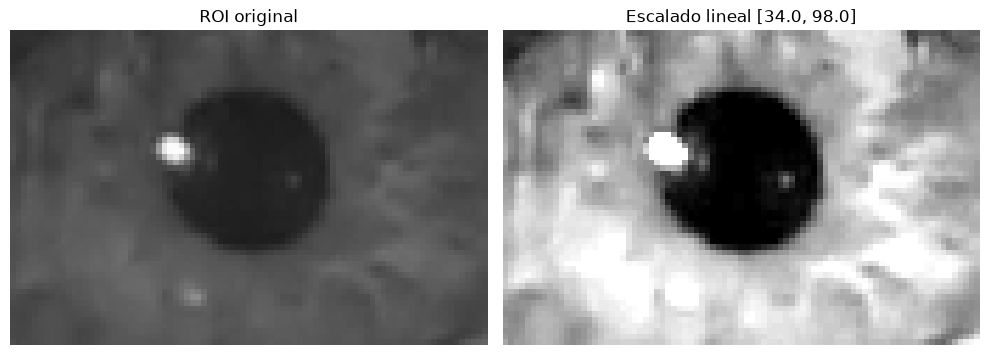

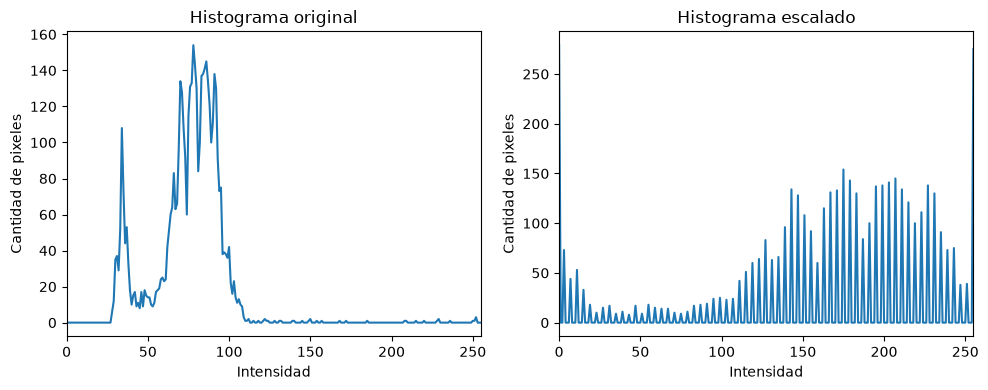

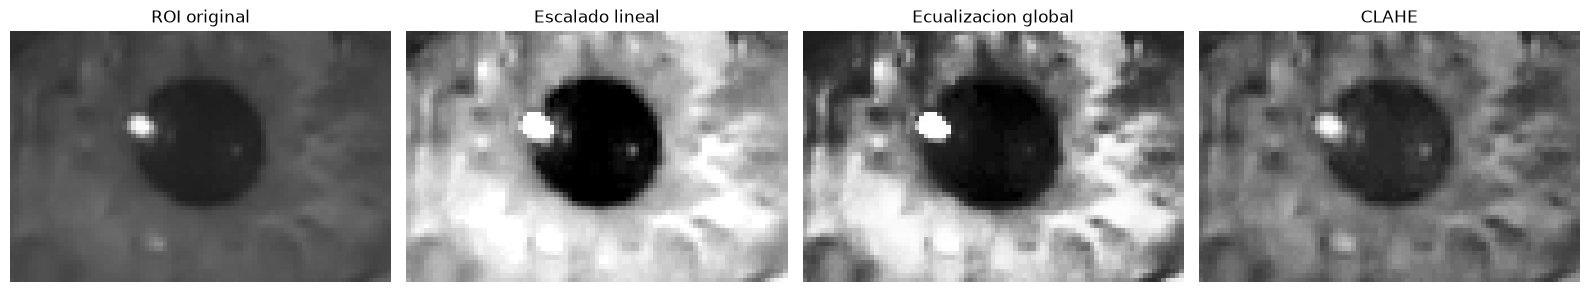

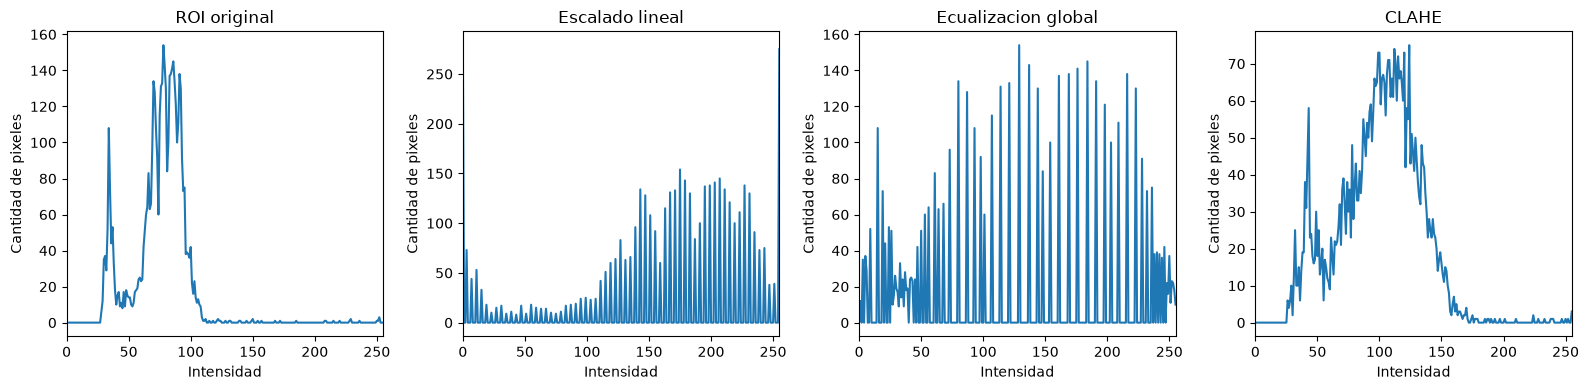

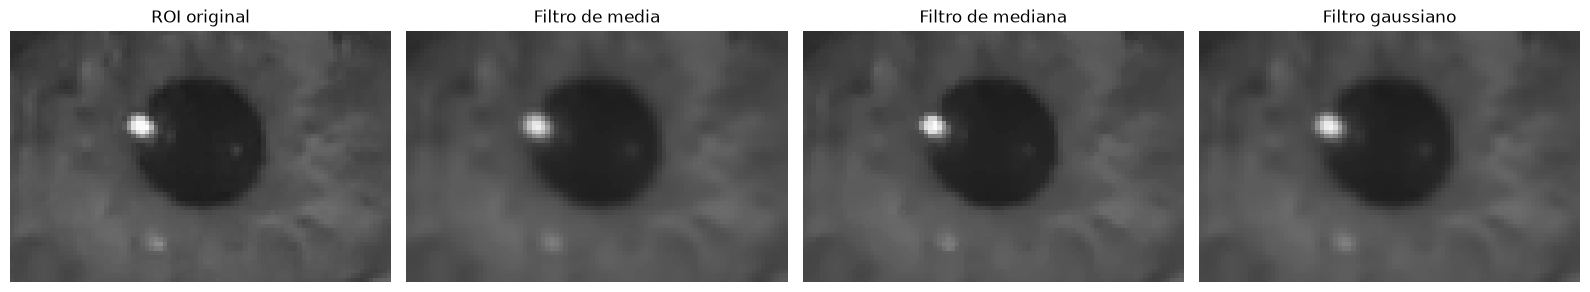

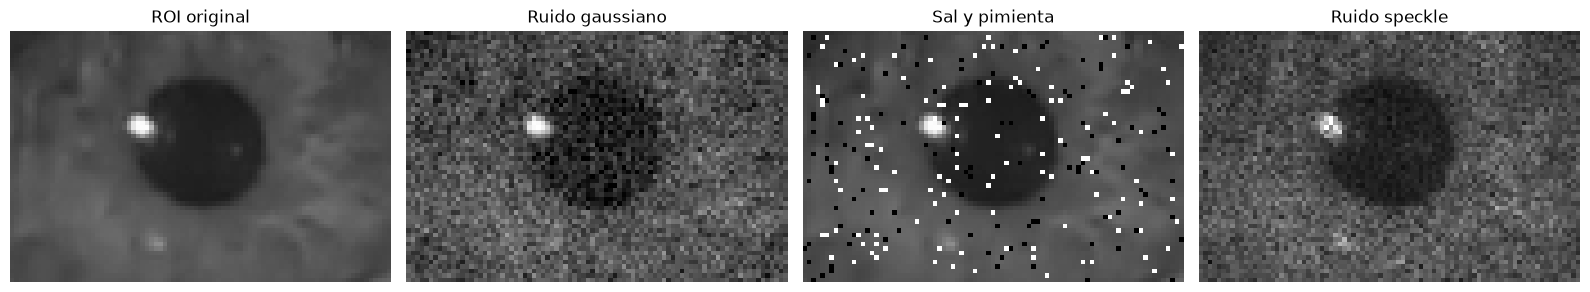

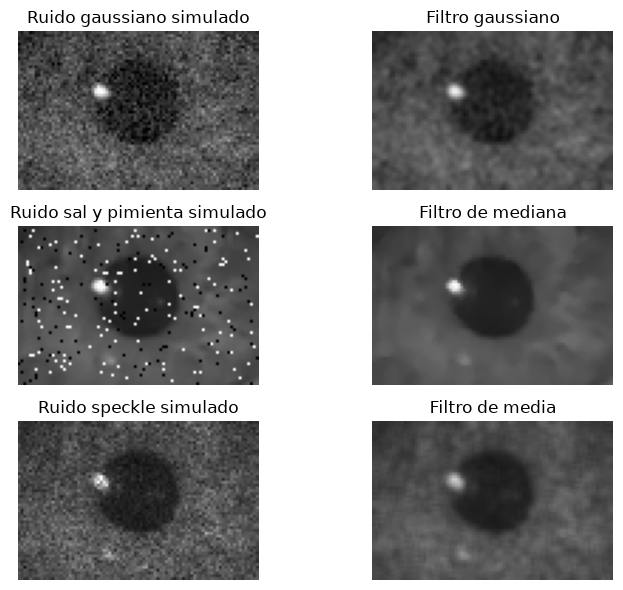

In [38]:
#1.2.1 

# Convertir el frame de BGR a escala de grises
frame_gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

# Aumentar el brillo sumando 50 a cada pixel
# np.clip limita las intensidades al rango [0, 255]
frame_brillo = np.clip(frame_gris.astype(float) + 50, 0, 255).astype("uint8")

# Aumentar el contraste multiplicando por 1.5
frame_contraste = np.clip(frame_gris.astype(float) * 1.5, 0, 255).astype("uint8")

# Visualizar las imagenes
fig, ax = plt.subplots(1, 3, figsize=(12, 4))

ax[0].imshow(frame_gris, cmap="gray", vmin=0, vmax=255)
ax[0].set_title("Frame original")

ax[1].imshow(frame_brillo, cmap="gray", vmin=0, vmax=255)
ax[1].set_title("Brillo +50")

ax[2].imshow(frame_contraste, cmap="gray", vmin=0, vmax=255)
ax[2].set_title("Contraste x1.5")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

# Calcular y comparar los histogramas
fig, ax = plt.subplots(1, 3, figsize=(12, 4))

imagenes = [frame_gris, frame_brillo, frame_contraste]
titulos = ["Histograma original", "Brillo +50", "Contraste x1.5"]

for i in range(3):
    histograma = cv2.calcHist([imagenes[i]], [0], None, [256], [0, 256])
    ax[i].plot(histograma)
    ax[i].set_yscale("log") #cambiamos la escala del eje y a logarítmica
    ax[i].set_title(titulos[i])
    ax[i].set_xlabel("Intensidad")
    ax[i].set_ylabel("Cantidad de pixeles")
    ax[i].set_xlim([0, 255])

plt.tight_layout()
plt.show()


# 1.2.2 Escalado por rango de interes
# Convertir la ROI a escala de grises
roi_gris = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)

# Definir el intervalo de intensidades de interes
f1 = np.percentile(roi_gris, 5)
f2 = np.percentile(roi_gris, 95)
#Para entender: f1 y f2 representan los límites inferior y superior del intervalo 
# que se desea expandir al rango completo de 0 a 255. Agarramos el 5% y el 95% de 
# de las intensidades de la ROI en escala de grises. De esta manera, el intervalo
# seleccionado contiene aproximadamente el 90% central de los valores de intensidad, 
# excluyendo los extremos de la distribución.

print(f"f1 = {f1:.1f}")
print(f"f2 = {f2:.1f}")

# Aplicar transformacion lineal: las intensidades entre f1 y f2 se expanden al rango 0-255 
#Los valores inferiores a f1 se les asigna 0 y los valores mayores a f2 se les asigna 255
roi_escalada = (roi_gris.astype(float) - f1) * 255 / (f2 - f1)

# Limitar el resultado al rango [0, 255]
roi_escalada = np.clip(roi_escalada, 0, 255).astype("uint8")

# Visualizar las imagenes
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].imshow(roi_gris, cmap="gray", vmin=0, vmax=255)
ax[0].set_title("ROI original")

ax[1].imshow(roi_escalada, cmap="gray", vmin=0, vmax=255)
ax[1].set_title(f"Escalado lineal [{f1:.1f}, {f2:.1f}]")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

# Comparar los histogramas
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

hist_original = cv2.calcHist([roi_gris], [0], None, [256], [0, 256])
hist_escalado = cv2.calcHist([roi_escalada], [0], None, [256], [0, 256])

ax[0].plot(hist_original)
ax[0].set_title("Histograma original")

ax[1].plot(hist_escalado)
ax[1].set_title("Histograma escalado")

for a in ax:
    a.set_xlabel("Intensidad")
    a.set_ylabel("Cantidad de pixeles")
    a.set_xlim([0, 255])

plt.tight_layout()
plt.show()

# 1.2.3 Ecualización del histograma

# Ecualizacion global
roi_ecualizada = cv2.equalizeHist(roi_gris)

# Ecualizacion local (CLAHE)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
roi_clahe = clahe.apply(roi_gris)

# Comparar las imagenes
fig, ax = plt.subplots(1, 4, figsize=(16, 4))

imagenes = [roi_gris, roi_escalada, roi_ecualizada, roi_clahe]
titulos = ["ROI original", "Escalado lineal", "Ecualizacion global", "CLAHE"]

for i in range(4):
    ax[i].imshow(imagenes[i], cmap="gray", vmin=0, vmax=255)
    ax[i].set_title(titulos[i])
    ax[i].axis("off")

plt.tight_layout()
plt.show()

# Comparar los histogramas
fig, ax = plt.subplots(1, 4, figsize=(16, 4))

for i in range(4):
    histograma = cv2.calcHist([imagenes[i]], [0], None, [256], [0, 256])

    ax[i].plot(histograma)
    ax[i].set_title(titulos[i])
    ax[i].set_xlabel("Intensidad")
    ax[i].set_ylabel("Cantidad de pixeles")
    ax[i].set_xlim([0, 255])

plt.tight_layout()
plt.show()


# 1.2.4 Analisis de ruido y filtrado espacial

# A. Aplicacion de filtros sobre la ROI original (sin ruido simulado)

# Filtro de media
roi_media = cv2.blur(roi_gris, (3, 3))

# Filtro de mediana
roi_mediana = cv2.medianBlur(roi_gris, 3)

# Filtro gaussiano
roi_filtro_gaussiano = cv2.GaussianBlur(roi_gris, (3, 3), 0)

# Comparar la imagen original con las tres filtradas
imagenes = [roi_gris, roi_media, roi_mediana, roi_filtro_gaussiano]
titulos = ["ROI original", "Filtro de media", "Filtro de mediana", "Filtro gaussiano"]

fig, ax = plt.subplots(1, 4, figsize=(16, 4))

for i in range(4):
    ax[i].imshow(imagenes[i], cmap="gray", vmin=0, vmax=255)
    ax[i].set_title(titulos[i])
    ax[i].axis("off")

plt.tight_layout()
plt.show()


# B. Simulacion de los distintos tipos de ruido

# Creamos un generador de numeros aleatorios
rng = np.random.default_rng(42)

# Matriz de gaussiano
ruido_gaussiano = rng.normal(0, 20, roi_gris.shape)

#Sumamos el ruido gaussiano a las intensidades originales
roi_gaussiana = np.clip(
    roi_gris.astype(float) + ruido_gaussiano, 0, 255
).astype("uint8")

# Ruido sal y pimienta
roi_sal_pimienta = roi_gris.copy()

#Seleccionamos aleatoriamente qué pixeles vamos a modificar para el ruido sal y pimienta
probabilidad = 0.05 #queremos modificar el 5% de los pixeles de la imagen
aleatorios = rng.random(roi_gris.shape) #generamos numeros aleatorios

roi_sal_pimienta[aleatorios < probabilidad / 2] = 0
roi_sal_pimienta[(aleatorios >= probabilidad / 2) &
                 (aleatorios < probabilidad)] = 255

# Ruido speckle
ruido_speckle = rng.normal(0, 0.2, roi_gris.shape)
roi_speckle = np.clip(
    roi_gris.astype(float) * (1 + ruido_speckle), 0, 255
).astype("uint8")

# Comparacion de los ruidos
imagenes_ruido = [
    roi_gris,
    roi_gaussiana,
    roi_sal_pimienta,
    roi_speckle
]

titulos_ruido = [
    "ROI original",
    "Ruido gaussiano",
    "Sal y pimienta",
    "Ruido speckle"
]

fig, ax = plt.subplots(1, 4, figsize=(16, 4))

for i in range(4):
    ax[i].imshow(imagenes_ruido[i], cmap="gray", vmin=0, vmax=255)
    ax[i].set_title(titulos_ruido[i])
    ax[i].axis("off")

plt.tight_layout()
plt.show()


# C. Aplicacion de filtros espaciales

# Aplicar filtro gaussiano al ruido gaussiano
roi_gaussiana_filtrada = cv2.GaussianBlur(roi_gaussiana, (3, 3), 0)

# Aplicar filtro de mediana al ruido sal y pimienta
roi_sal_pimienta_filtrada = cv2.medianBlur(roi_sal_pimienta, 3)

# Aplicar filtro de media al ruido speckle
roi_speckle_filtrada = cv2.blur(roi_speckle, (3, 3))

# Comparar imagenes antes y despues del filtrado
imagenes = [
    roi_gaussiana,
    roi_gaussiana_filtrada,
    roi_sal_pimienta,
    roi_sal_pimienta_filtrada,
    roi_speckle,
    roi_speckle_filtrada
]

titulos = [
    "Ruido gaussiano simulado",
    "Filtro gaussiano",
    "Ruido sal y pimienta simulado",
    "Filtro de mediana",
    "Ruido speckle simulado",
    "Filtro de media"
]

fig, ax = plt.subplots(3, 2, figsize=(8, 6))

for i in range(3):
    for j in range(2):
        ax[i, j].imshow(imagenes[i*2+j], cmap="gray", vmin=0, vmax=255)
        ax[i, j].set_title(titulos[i*2+j])
        ax[i, j].axis("off")

plt.tight_layout()
plt.show()


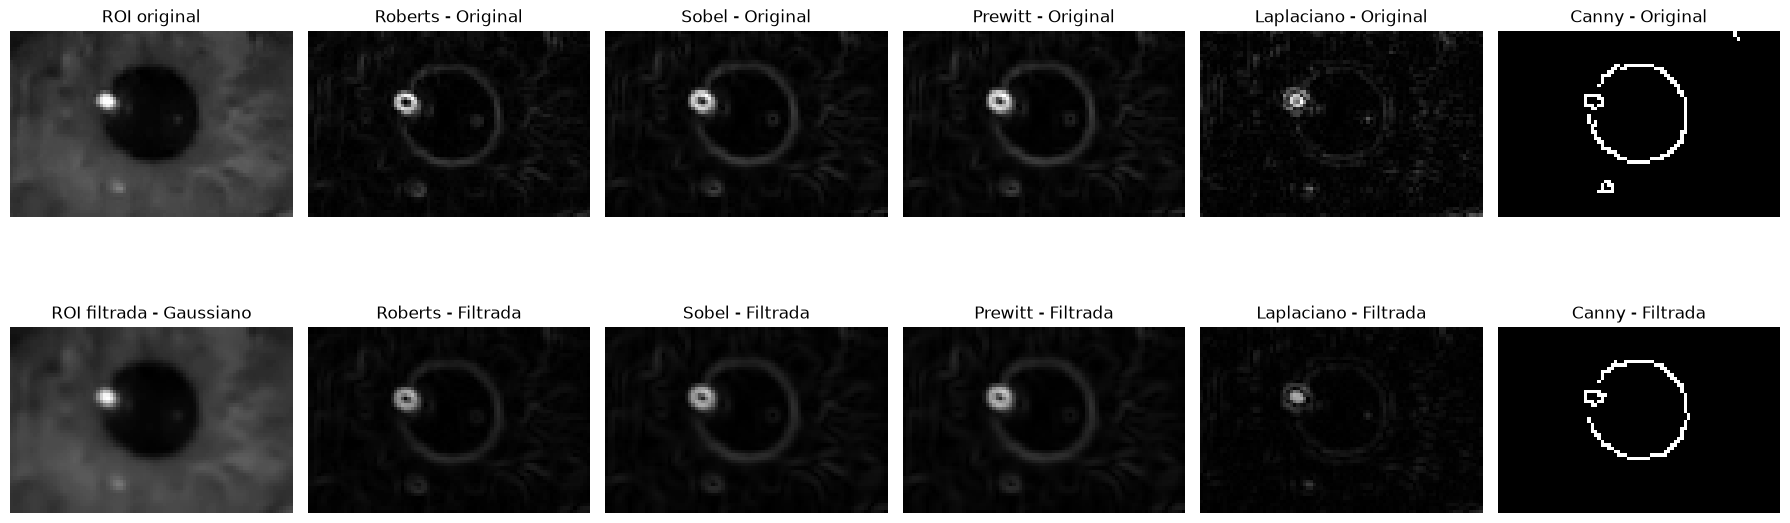

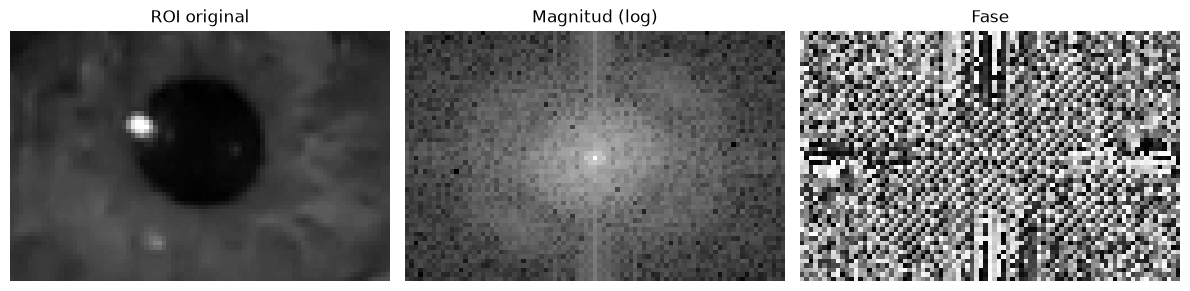

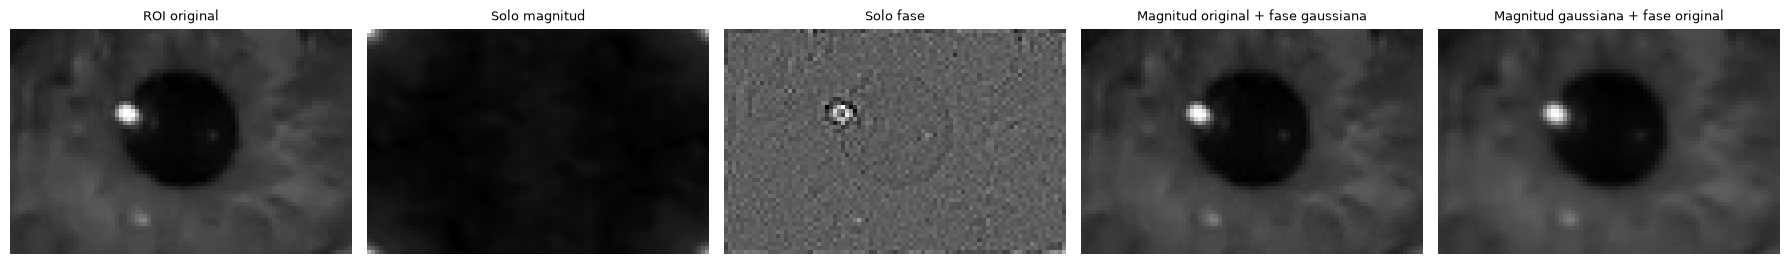

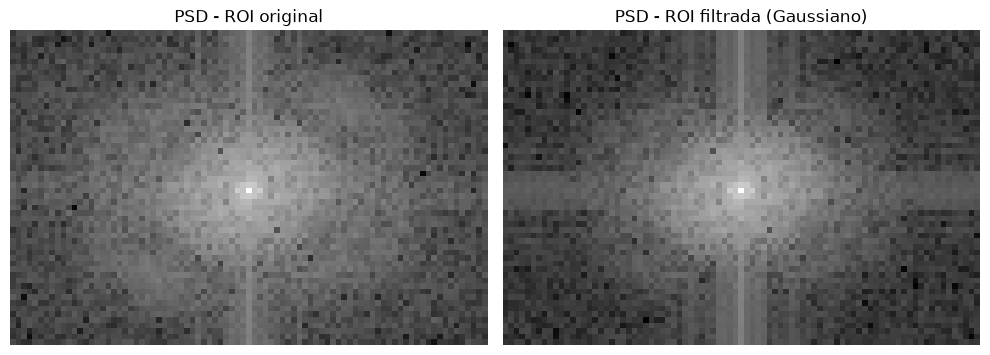

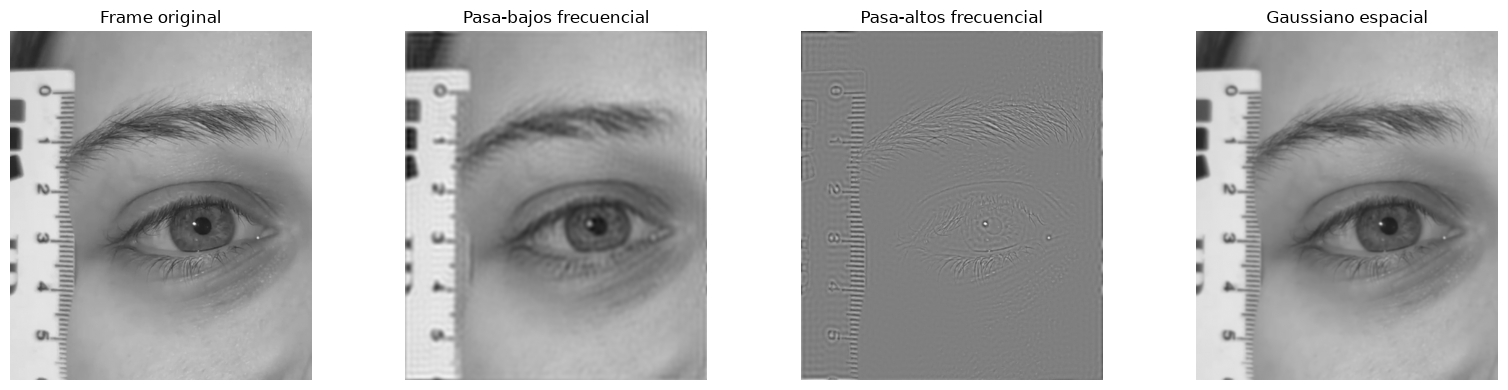

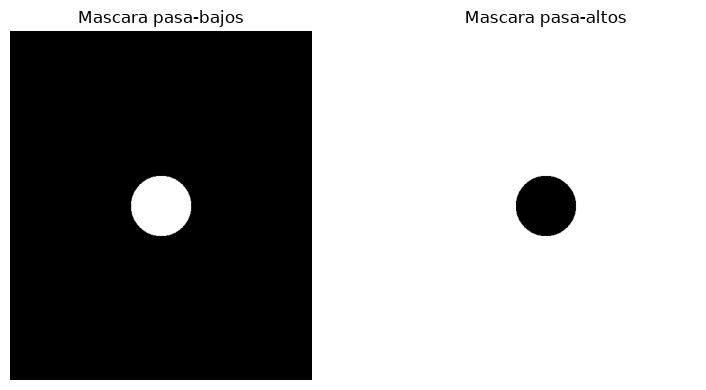


--- Comparacion PSNR y SSIM ---

Filtro: Media
PSNR: 39.57 dB
SSIM: 0.9769

Filtro: Mediana
PSNR: 42.42 dB
SSIM: 0.9834

Filtro: Gaussiano
PSNR: 41.75 dB
SSIM: 0.9858


In [39]:
# 1.3 Deteccion de bordes y dominio frecuencial

# 1.3.1 Deteccion de bordes

# Imagen original y filtrada en el punto 1.2.4
imagen_original = roi_gris
imagen_filtrada = roi_filtro_gaussiano

# Funcion para aplicar los cinco operadores
def detectar_bordes(imagen):

    imagen_float = imagen.astype(np.float32)

    # Roberts
    kernel_roberts_x = np.array([[1, 0],
                                 [0, -1]], dtype=np.float32)

    kernel_roberts_y = np.array([[0, 1],
                                 [-1, 0]], dtype=np.float32)

    roberts_x = cv2.filter2D(
        imagen_float, cv2.CV_32F, kernel_roberts_x
    )
    roberts_y = cv2.filter2D(
        imagen_float, cv2.CV_32F, kernel_roberts_y
    )

    roberts = cv2.magnitude(roberts_x, roberts_y)

    # Sobel
    sobel_x = cv2.Sobel(imagen, cv2.CV_32F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(imagen, cv2.CV_32F, 0, 1, ksize=3)

    sobel = cv2.magnitude(sobel_x, sobel_y)

    # Prewitt
    kernel_prewitt_x = np.array([[-1, 0, 1],
                                 [-1, 0, 1],
                                 [-1, 0, 1]], dtype=np.float32)

    kernel_prewitt_y = np.array([[-1, -1, -1],
                                 [0, 0, 0],
                                 [1, 1, 1]], dtype=np.float32)

    prewitt_x = cv2.filter2D(
        imagen_float, cv2.CV_32F, kernel_prewitt_x
    )
    prewitt_y = cv2.filter2D(
        imagen_float, cv2.CV_32F, kernel_prewitt_y
    )

    prewitt = cv2.magnitude(prewitt_x, prewitt_y)

    # Laplaciano
    laplaciano = cv2.Laplacian(
        imagen, cv2.CV_32F, ksize=3
    )
    laplaciano = np.abs(laplaciano)

    # Canny
    canny = cv2.Canny(imagen, 50, 150)

    return [roberts, sobel, prewitt, laplaciano, canny]


# Aplicar los operadores a ambas imagenes
bordes_original = detectar_bordes(imagen_original)
bordes_filtrada = detectar_bordes(imagen_filtrada)

nombres = ["Roberts", "Sobel", "Prewitt",
           "Laplaciano", "Canny"]

# Comparacion visual
fig, ax = plt.subplots(2, 6, figsize=(18, 7))

ax[0, 0].imshow(imagen_original, cmap="gray")
ax[0, 0].set_title("ROI original")

ax[1, 0].imshow(imagen_filtrada, cmap="gray")
ax[1, 0].set_title("ROI filtrada - Gaussiano")

for i in range(5):

    # Usamos la misma escala por operador
    # para comparar original y filtrada
    limite = max(
        np.max(bordes_original[i]),
        np.max(bordes_filtrada[i]),
        1
    )

    ax[0, i+1].imshow(
        bordes_original[i], cmap="gray",
        vmin=0, vmax=limite
    )
    ax[0, i+1].set_title(nombres[i] + " - Original")

    ax[1, i+1].imshow(
        bordes_filtrada[i], cmap="gray",
        vmin=0, vmax=limite
    )
    ax[1, i+1].set_title(nombres[i] + " - Filtrada")

for fila in ax:
    for a in fila:
        a.axis("off")

plt.tight_layout()
plt.show()


# 1.3.2 Transformada de Fourier 2D

# Calcular la transformada de Fourier de la ROI original
F_original = np.fft.fft2(roi_gris)

# Centrar las frecuencias bajas
F_original_centrada = np.fft.fftshift(F_original)

# Obtener magnitud y fase
magnitud_original = np.abs(F_original_centrada)
fase_original = np.angle(F_original_centrada)

# Representar la magnitud en escala logaritmica
magnitud_log = np.log1p(magnitud_original)

# Visualizar la imagen, magnitud y fase
fig, ax = plt.subplots(1, 3, figsize=(12, 4))

ax[0].imshow(roi_gris, cmap="gray")
ax[0].set_title("ROI original")

ax[1].imshow(magnitud_log, cmap="gray")
ax[1].set_title("Magnitud (log)")

ax[2].imshow(fase_original, cmap="gray",
             vmin=-np.pi, vmax=np.pi)
ax[2].set_title("Fase")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()


# A. Reconstruccion utilizando solo magnitud

# Conservar magnitud y establecer fase igual a cero
F_solo_magnitud = magnitud_original

recon_magnitud = np.fft.ifft2(
    np.fft.ifftshift(F_solo_magnitud)
).real


# B. Reconstruccion utilizando solo fase

# Conservar fase y establecer magnitud igual a uno
F_solo_fase = np.exp(1j * fase_original)

recon_fase = np.fft.ifft2(
    np.fft.ifftshift(F_solo_fase)
).real


# C. Cruzar magnitud y fase de dos imagenes

# Fourier de la ROI filtrada con gaussiano
F_gaussiana = np.fft.fftshift(
    np.fft.fft2(roi_filtro_gaussiano)
)

magnitud_gaussiana = np.abs(F_gaussiana)
fase_gaussiana = np.angle(F_gaussiana)

# Magnitud original + fase gaussiana
F_cruzada_1 = magnitud_original * np.exp(
    1j * fase_gaussiana
)

recon_cruzada_1 = np.fft.ifft2(
    np.fft.ifftshift(F_cruzada_1)
).real

# Magnitud gaussiana + fase original
F_cruzada_2 = magnitud_gaussiana * np.exp(
    1j * fase_original
)

recon_cruzada_2 = np.fft.ifft2(
    np.fft.ifftshift(F_cruzada_2)
).real


# D. Visualizacion comparativa

# Normalizar cada reconstruccion para visualizarla
def normalizar_imagen(imagen):
    return cv2.normalize(
        imagen.astype(np.float32),
        None, 0, 255, cv2.NORM_MINMAX
    )

imagenes = [
    roi_gris,
    recon_magnitud,
    recon_fase,
    recon_cruzada_1,
    recon_cruzada_2
]

titulos = [
    "ROI original",
    "Solo magnitud",
    "Solo fase",
    "Magnitud original + fase gaussiana",
    "Magnitud gaussiana + fase original"
]

fig, ax = plt.subplots(1, 5, figsize=(18, 4))

for i in range(5):
    ax[i].imshow(
        normalizar_imagen(imagenes[i]),
        cmap="gray"
    )
    ax[i].set_title(titulos[i], fontsize=9)
    ax[i].axis("off")

plt.tight_layout()
plt.show()


# 1.3.3 Densidad espectral de potencia (PSD)

# Calcular la transformada de Fourier de la ROI original y filtrada
F_original_psd = np.fft.fftshift(
    np.fft.fft2(roi_gris.astype(float))
)

F_gaussiana_psd = np.fft.fftshift(
    np.fft.fft2(roi_filtro_gaussiano.astype(float))
)

# Calcular la PSD como el cuadrado de la magnitud
psd_original = np.abs(F_original_psd)**2
psd_gaussiana = np.abs(F_gaussiana_psd)**2

# Aplicar escala logaritmica para visualizar mejor
psd_original_log = np.log1p(psd_original)
psd_gaussiana_log = np.log1p(psd_gaussiana)

# Usar la misma escala para comparar las dos imagenes
escala_maxima = max(
    np.max(psd_original_log),
    np.max(psd_gaussiana_log)
)

# Visualizar las PSD
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].imshow(
    psd_original_log,
    cmap="gray",
    vmin=0,
    vmax=escala_maxima
)
ax[0].set_title("PSD - ROI original")

ax[1].imshow(
    psd_gaussiana_log,
    cmap="gray",
    vmin=0,
    vmax=escala_maxima
)
ax[1].set_title("PSD - ROI filtrada (Gaussiano)")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()


# 1.3.4 Filtrado en el dominio frecuencial

# Calcular la transformada de Fourier del frame completo
F_frame = np.fft.fft2(frame_gris.astype(float))

# Centrar las frecuencias bajas
F_frame_centrada = np.fft.fftshift(F_frame)

# Obtener las dimensiones del frame
alto_frame, ancho_frame = frame_gris.shape

# Crear coordenadas para calcular la distancia al centro
Y, X = np.ogrid[:alto_frame, :ancho_frame]

centro_y = alto_frame // 2
centro_x = ancho_frame // 2

distancia = np.sqrt(
    (X - centro_x)**2 + (Y - centro_y)**2
)

# Definir una frecuencia de corte inicial
D0 = 0.10 * min(alto_frame, ancho_frame)

# Crear las mascaras de filtrado
# Pasa-bajos: conserva frecuencias cercanas al centro
H_pasabajos = (distancia <= D0).astype(float)

# Pasa-altos: conserva frecuencias alejadas del centro
H_pasaaltos = (distancia > D0).astype(float)

# Aplicar las mascaras en el dominio frecuencial
F_pasabajos = F_frame_centrada * H_pasabajos
F_pasaaltos = F_frame_centrada * H_pasaaltos

# Reconstruir las imagenes mediante transformada inversa
frame_pasabajos = np.fft.ifft2(
    np.fft.ifftshift(F_pasabajos)
).real

frame_pasaaltos = np.fft.ifft2(
    np.fft.ifftshift(F_pasaaltos)
).real

# Aplicar filtro gaussiano en el dominio espacial
# para comparar ambos tipos de filtrado
frame_gaussiano = cv2.GaussianBlur(
    frame_gris, (5, 5), 0
)

# Visualizar las imagenes
fig, ax = plt.subplots(1, 4, figsize=(16, 4))

ax[0].imshow(frame_gris, cmap="gray", vmin=0, vmax=255)
ax[0].set_title("Frame original")

ax[1].imshow(frame_pasabajos, cmap="gray",
             vmin=0, vmax=255)
ax[1].set_title("Pasa-bajos frecuencial")

# El pasa-altos puede contener valores negativos.
# Centramos la visualizacion en cero para observar bordes.
limite = max(np.max(np.abs(frame_pasaaltos)), 1)

ax[2].imshow(frame_pasaaltos, cmap="gray",
             vmin=-limite, vmax=limite)
ax[2].set_title("Pasa-altos frecuencial")

ax[3].imshow(frame_gaussiano, cmap="gray",
             vmin=0, vmax=255)
ax[3].set_title("Gaussiano espacial")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()


# Visualizar las mascaras frecuenciales
fig, ax = plt.subplots(1, 2, figsize=(8, 4))

ax[0].imshow(H_pasabajos, cmap="gray")
ax[0].set_title("Mascara pasa-bajos")

ax[1].imshow(H_pasaaltos, cmap="gray")
ax[1].set_title("Mascara pasa-altos")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

# Preguntas finales del 1.3 - PSNR y SSIM

from skimage.metrics import structural_similarity as ssim

# Imagen de referencia: ROI original
imagen_referencia = roi_gris

# Imagenes obtenidas con los filtros espaciales del 1.2.4
imagenes_filtradas = {
    "Media": roi_media,
    "Mediana": roi_mediana,
    "Gaussiano": roi_filtro_gaussiano
}

# Calcular PSNR y SSIM para cada filtro
print("\n--- Comparacion PSNR y SSIM ---")

for nombre, imagen in imagenes_filtradas.items():

    # PSNR: compara las diferencias de intensidad
    psnr_valor = cv2.PSNR(imagen_referencia, imagen)

    # SSIM: compara la similitud estructural
    ssim_valor = ssim(
        imagen_referencia,
        imagen,
        data_range=255
    )

    print(f"\nFiltro: {nombre}")
    print(f"PSNR: {psnr_valor:.2f} dB")
    print(f"SSIM: {ssim_valor:.4f}")




Umbral calculado por Otsu: 62.0


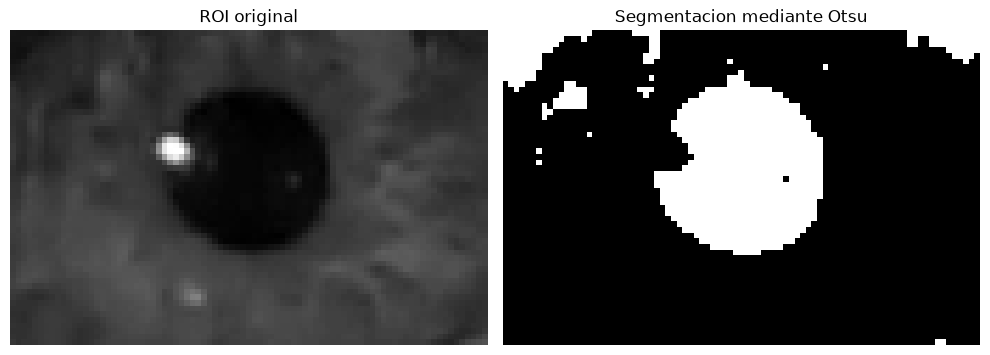

K=2: centros = [42.31513 82.57202]
K=3: centros = [37.63319 71.92142 91.49194]
K=4: centros = [ 37.63319  71.54069  89.98051 214.83333]
K=5: centros = [ 37.155922  67.24404   81.074776  94.3583   222.25    ]


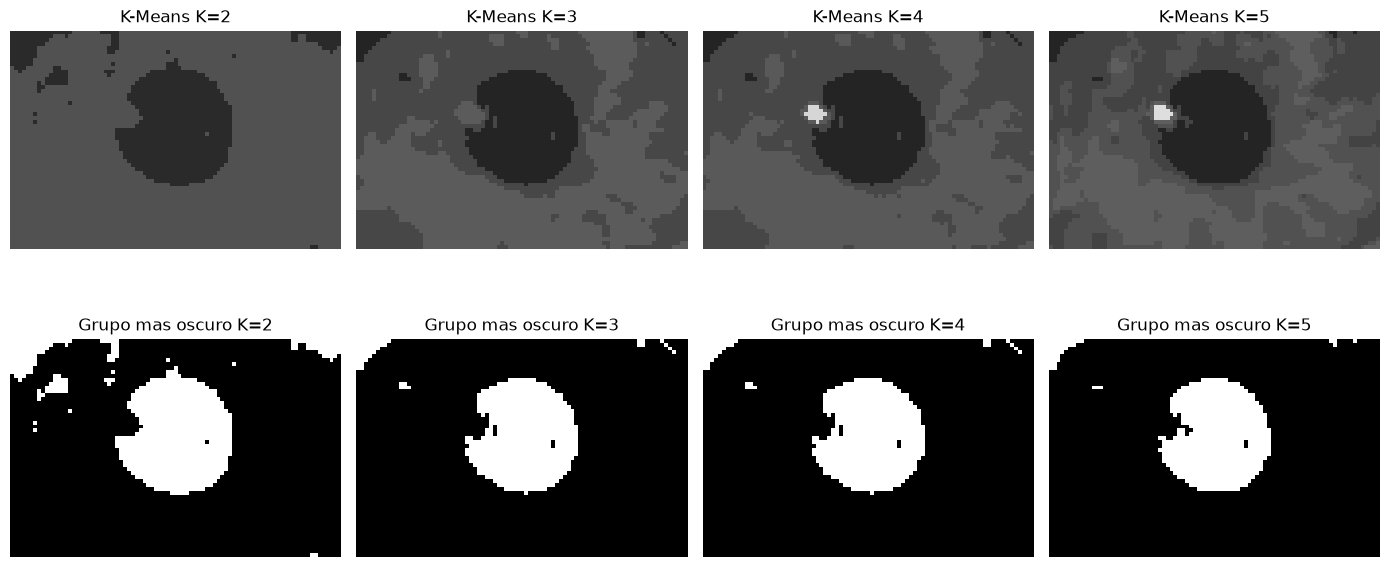

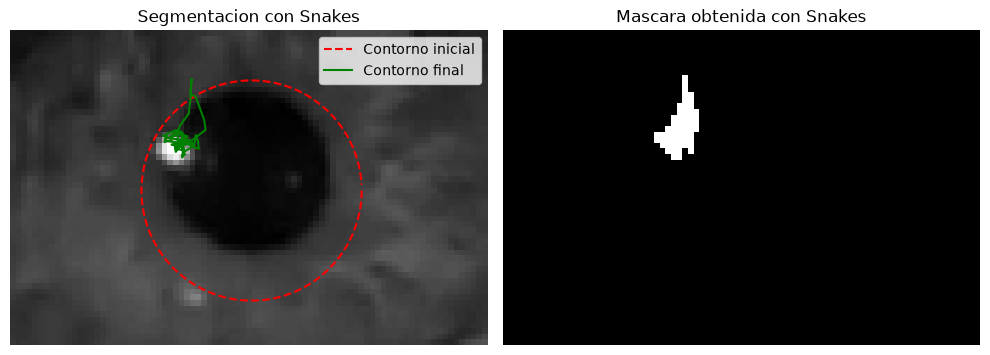

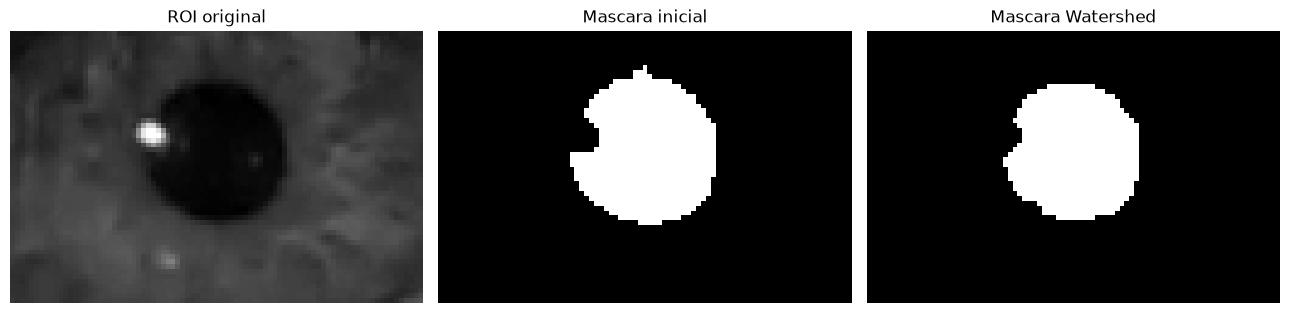

Se cargo la mascara de referencia guardada

--- Comparacion de segmentaciones mediante Dice ---
Otsu: Dice = 0.8240
K-Means K=2: Dice = 0.8240
K-Means K=3: Dice = 0.9065
K-Means K=4: Dice = 0.9065
K-Means K=5: Dice = 0.9096
Snakes: Dice = 0.1099
Watershed: Dice = 0.9434

Mejor metodo: Watershed
Dice obtenido: 0.9434


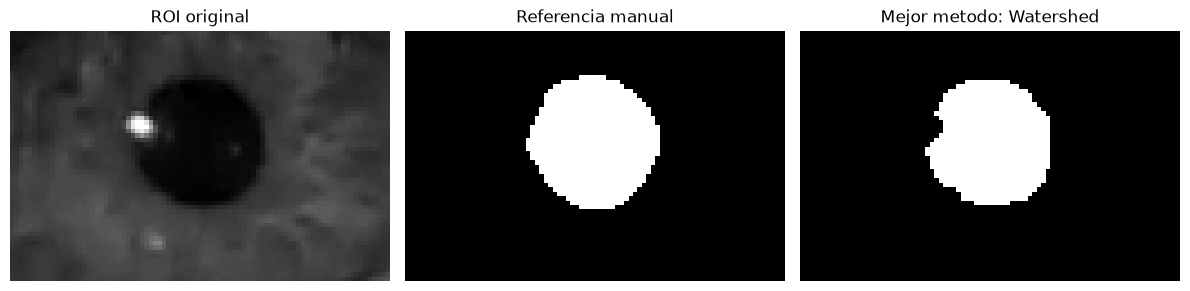

Metodo seleccionado para morfologia: Watershed


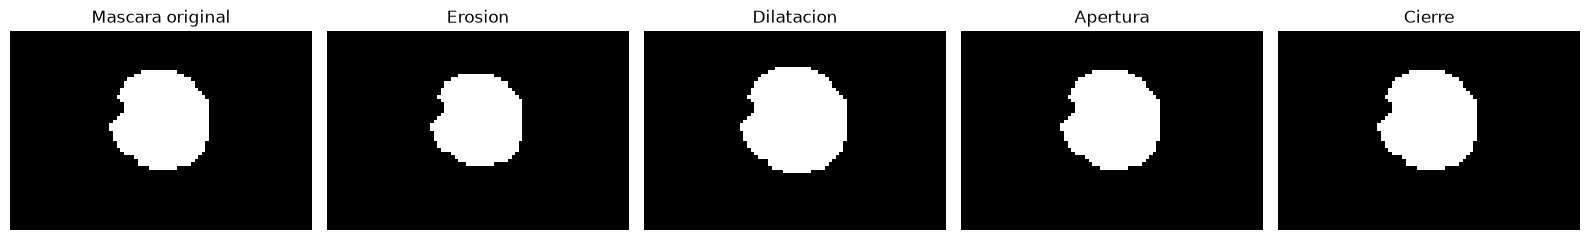

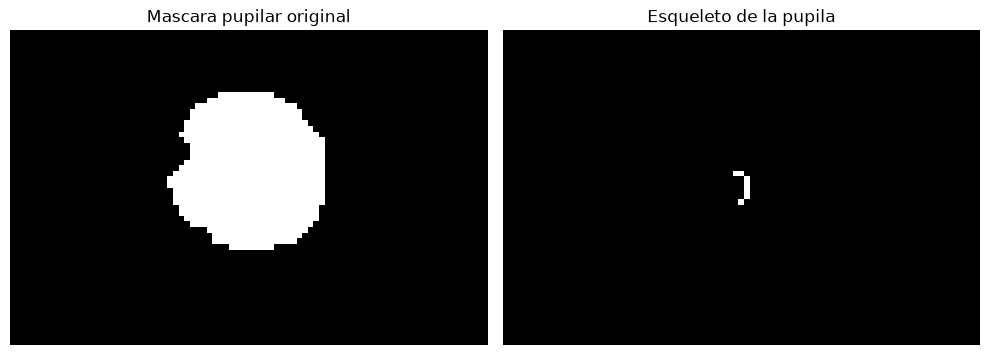


--- Comparacion de operaciones morfologicas ---

Operacion: Sin morfologia
Dice = 0.9434
IoU  = 0.8928

Operacion: Erosion
Dice = 0.8874
IoU  = 0.7976

Operacion: Dilatacion
Dice = 0.9563
IoU  = 0.9163

Operacion: Apertura
Dice = 0.9425
IoU  = 0.8913

Operacion: Cierre
Dice = 0.9434
IoU  = 0.8928

--- Resultado final del Modulo 2 ---
Metodo de segmentacion: Watershed
Operacion morfologica: Dilatacion
Dice final: 0.9563
IoU final: 0.9163


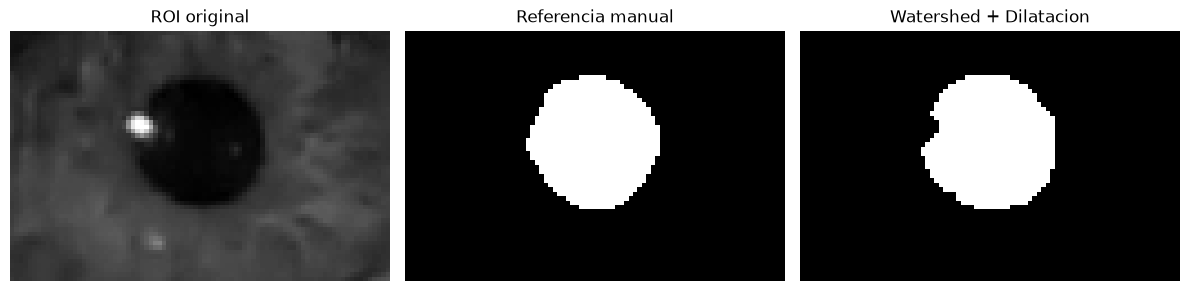


Mascara final guardada en: /Users/milenaszwarcberg/Documents/ITBA/2026 2C/PSIB/Guia_imagenes/resultados/mascara_pupila_final.png


In [40]:
# MODULO 2: Segmentacion y morfologia matematica de la pupila

# 2.1.1 Umbralizacion automatica de Otsu

# Utilizamos la ROI original en escala de grises
imagen_otsu = roi_gris

# Calcular automaticamente el umbral mediante Otsu
umbral, mascara_otsu = cv2.threshold(
    imagen_otsu,
    0,
    255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

print(f"Umbral calculado por Otsu: {umbral}")

# Visualizar la ROI y la mascara obtenida
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].imshow(imagen_otsu, cmap="gray")
ax[0].set_title("ROI original")

ax[1].imshow(mascara_otsu, cmap="gray", vmin=0, vmax=255)
ax[1].set_title("Segmentacion mediante Otsu")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()


# 2.1.2 Segmentacion mediante K-Means

# Trabajamos con la ROI original en escala de grises
imagen_kmeans = roi_gris

# Convertir la imagen en una lista de pixeles
pixeles = imagen_kmeans.reshape(-1, 1).astype(np.float32)

# Criterio de finalizacion del algoritmo
criterio = (
    cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER,
    100,
    0.2
)

# Guardar las mascaras para compararlas despues
mascaras_kmeans = {}

fig, ax = plt.subplots(2, 4, figsize=(14, 7))

for i, k in enumerate([2, 3, 4, 5]):

    # Aplicar K-Means
    _, etiquetas, centros = cv2.kmeans(
        pixeles,
        k,
        None,
        criterio,
        10,
        cv2.KMEANS_PP_CENTERS
    )

    # Reconstruir la imagen agrupada
    centros_uint8 = np.uint8(centros)

    imagen_agrupada = centros_uint8[
        etiquetas.flatten()
    ].reshape(imagen_kmeans.shape)

    # Identificar el grupo de menor intensidad
    grupo_oscuro = np.argmin(centros.flatten())

    # Crear mascara binaria
    mascara = (
        etiquetas.flatten() == grupo_oscuro
    ).reshape(imagen_kmeans.shape).astype(np.uint8) * 255

    mascaras_kmeans[k] = mascara

    # Visualizar imagen agrupada
    ax[0, i].imshow(
        imagen_agrupada, cmap="gray",
        vmin=0, vmax=255
    )
    ax[0, i].set_title(f"K-Means K={k}")

    # Visualizar mascara del grupo mas oscuro
    ax[1, i].imshow(
        mascara, cmap="gray",
        vmin=0, vmax=255
    )
    ax[1, i].set_title(f"Grupo mas oscuro K={k}")

    print(f"K={k}: centros = {np.sort(centros.flatten())}")

for fila in ax:
    for a in fila:
        a.axis("off")

plt.tight_layout()
plt.show()



# 2.1.3 Segmentacion mediante contornos activos (Snakes)

from skimage.segmentation import active_contour
from skimage.filters import gaussian

# Imagen de trabajo en escala de grises
imagen_snake = roi_gris.astype(float) / 255.0

# Suavizar para reducir pequenas variaciones
imagen_snake_suavizada = gaussian(
    imagen_snake, sigma=1
)

# Dimensiones de la ROI
alto, ancho = roi_gris.shape

# Definir contorno inicial circular
centro_x = ancho / 2
centro_y = alto / 2

radio_inicial = min(alto, ancho) * 0.35

# Crear puntos del circulo
angulo = np.linspace(0, 2*np.pi, 120, endpoint=False)

# Coordenadas en formato fila, columna
contorno_inicial = np.array([
    centro_y + radio_inicial * np.sin(angulo),
    centro_x + radio_inicial * np.cos(angulo)
]).T

# Aplicar contorno activo
contorno_final = active_contour(
    imagen_snake_suavizada,
    contorno_inicial,
    alpha=0.015,
    beta=10,
    gamma=0.001,
    w_line=0,
    w_edge=1,
    max_num_iter=2500,
    boundary_condition="periodic"
)

# Crear mascara binaria a partir del contorno final
mascara_snake = np.zeros_like(roi_gris, dtype=np.uint8)

# OpenCV utiliza coordenadas columna, fila
puntos_snake = np.round(
    contorno_final[:, ::-1]
).astype(np.int32)

cv2.fillPoly(
    mascara_snake,
    [puntos_snake],
    255
)

# Visualizar el contorno inicial y final
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].imshow(roi_gris, cmap="gray")
ax[0].plot(
    contorno_inicial[:, 1],
    contorno_inicial[:, 0],
    "--r",
    label="Contorno inicial"
)
ax[0].plot(
    contorno_final[:, 1],
    contorno_final[:, 0],
    "-g",
    label="Contorno final"
)
ax[0].set_title("Segmentacion con Snakes")
ax[0].legend()

ax[1].imshow(
    mascara_snake,
    cmap="gray",
    vmin=0, vmax=255
)
ax[1].set_title("Mascara obtenida con Snakes")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()


# 2.1.4 Segmentacion mediante Watershed

# Imagen de trabajo
imagen_ws = roi_gris.copy()

# Suavizado gaussiano para reducir variaciones locales
imagen_ws_filtrada = cv2.GaussianBlur(
    imagen_ws, (3, 3), 0
)

# Utilizar la mascara de Otsu para definir regiones iniciales
binaria = (mascara_otsu > 0).astype(np.uint8)

# Componentes conectadas para identificar la pupila
cantidad, etiquetas, estadisticas, centroides = (
    cv2.connectedComponentsWithStats(binaria, 8)
)

alto_ws, ancho_ws = imagen_ws.shape
centro_roi = np.array([ancho_ws / 2, alto_ws / 2])

# Elegir la componente mas cercana al centro de la ROI
componentes = list(range(1, cantidad))

componente_pupila = min(
    componentes,
    key=lambda i: np.linalg.norm(
        centroides[i] - centro_roi
    )
)

# Mascara aproximada de la pupila
mascara_inicial = (
    etiquetas == componente_pupila
).astype(np.uint8)

# Limpiar pequenas irregularidades
kernel_ws = np.ones((3, 3), np.uint8)

mascara_inicial = cv2.morphologyEx(
    mascara_inicial,
    cv2.MORPH_CLOSE,
    kernel_ws
)

# Crear marcadores para Watershed
# 0 = zona desconocida
# 1 = fondo
# 2 = pupila

marcadores = np.zeros_like(
    imagen_ws, dtype=np.int32
)

# Definir fondo seguro mediante dilatacion
region_dilatada = cv2.dilate(
    mascara_inicial, kernel_ws, iterations=3
)

marcadores[region_dilatada == 0] = 1

# Definir pupila segura mediante erosion
pupila_segura = cv2.erode(
    mascara_inicial, kernel_ws, iterations=2
)

marcadores[pupila_segura == 1] = 2

# Convertir la imagen a BGR para cv2.watershed
imagen_ws_bgr = cv2.cvtColor(
    imagen_ws_filtrada, cv2.COLOR_GRAY2BGR
)

# Aplicar Watershed
marcadores_resultado = cv2.watershed(
    imagen_ws_bgr, marcadores.copy()
)

# Obtener mascara final de la pupila
mascara_watershed = (
    marcadores_resultado == 2
).astype(np.uint8) * 255

# Visualizar resultados
fig, ax = plt.subplots(1, 3, figsize=(13, 4))

ax[0].imshow(imagen_ws, cmap="gray")
ax[0].set_title("ROI original")

ax[1].imshow(
    mascara_inicial, cmap="gray",
    vmin=0, vmax=1
)
ax[1].set_title("Mascara inicial")

ax[2].imshow(
    mascara_watershed, cmap="gray",
    vmin=0, vmax=255
)
ax[2].set_title("Mascara Watershed")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()


# 2.1.5 Comparacion de los metodos mediante Dice

# A. Crear o cargar la mascara de referencia manual

REFERENCIA_PATH = CARPETA_PROYECTO / "imagenes" / "mascara_referencia.png"

if REFERENCIA_PATH.exists():

    mascara_referencia = cv2.imread(
        str(REFERENCIA_PATH),
        cv2.IMREAD_GRAYSCALE
    )

    if mascara_referencia.shape != roi_gris.shape:
        raise ValueError(
            "La mascara de referencia no tiene las dimensiones de la ROI"
        )

    print("Se cargo la mascara de referencia guardada")

else:

    # Mostrar la ROI para marcar manualmente la pupila
    fig, ax = plt.subplots(figsize=(7, 6))

    ax.imshow(roi_gris, cmap="gray", vmin=0, vmax=255)
    ax.set_title(
        "Marcar puntos alrededor del contorno pupilar\n"
        "Presionar Enter para finalizar"
    )

    print("Hace clic alrededor del borde real de la pupila.")
    print("Presiona Enter cuando termines.")

    puntos = plt.ginput(n=-1, timeout=0)
    plt.close(fig)

    if len(puntos) < 3:
        raise ValueError(
            "Se necesitan al menos 3 puntos para definir el contorno"
        )

    # Convertir los puntos seleccionados a coordenadas de pixeles
    puntos = np.round(puntos).astype(np.int32)

    # Crear mascara binaria manual
    mascara_referencia = np.zeros_like(
        roi_gris, dtype=np.uint8
    )

    cv2.fillPoly(
        mascara_referencia,
        [puntos],
        255
    )

    # Guardar para reutilizar la misma referencia
    REFERENCIA_PATH.parent.mkdir(
        parents=True, exist_ok=True
    )

    cv2.imwrite(
        str(REFERENCIA_PATH),
        mascara_referencia
    )


# B. Funcion para calcular Dice

def calcular_dice(mascara1, mascara2):

    # Convertir ambas mascaras a booleanas
    m1 = mascara1 > 0
    m2 = mascara2 > 0

    interseccion = np.logical_and(m1, m2).sum()

    total = m1.sum() + m2.sum()

    if total == 0:
        return 1.0

    dice = 2 * interseccion / total

    return dice


# C. Comparar los cuatro metodos

mascaras_segmentacion = {
    "Otsu": mascara_otsu,
    "K-Means K=2": mascaras_kmeans[2],
    "K-Means K=3": mascaras_kmeans[3],
    "K-Means K=4": mascaras_kmeans[4],
    "K-Means K=5": mascaras_kmeans[5],
    "Snakes": mascara_snake,
    "Watershed": mascara_watershed
}

resultados_dice = {}

print("\n--- Comparacion de segmentaciones mediante Dice ---")

for nombre, mascara in mascaras_segmentacion.items():

    valor_dice = calcular_dice(
        mascara_referencia,
        mascara
    )

    resultados_dice[nombre] = valor_dice

    print(f"{nombre}: Dice = {valor_dice:.4f}")


# D. Identificar el metodo con mayor Dice

mejor_metodo = max(
    resultados_dice,
    key=resultados_dice.get
)

mejor_mascara = mascaras_segmentacion[mejor_metodo].copy()

print(f"\nMejor metodo: {mejor_metodo}")
print(f"Dice obtenido: {resultados_dice[mejor_metodo]:.4f}")


# E. Visualizar la referencia y el mejor resultado

fig, ax = plt.subplots(1, 3, figsize=(12, 4))

ax[0].imshow(roi_gris, cmap="gray")
ax[0].set_title("ROI original")

ax[1].imshow(
    mascara_referencia,
    cmap="gray",
    vmin=0, vmax=255
)
ax[1].set_title("Referencia manual")

ax[2].imshow(
    mejor_mascara,
    cmap="gray",
    vmin=0, vmax=255
)
ax[2].set_title(f"Mejor metodo: {mejor_metodo}")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()



# 2.2.1 Operaciones morfologicas

# Utilizar la mascara con mayor Dice del apartado 2.1
mascara_base = mejor_mascara.copy()

print(f"Metodo seleccionado para morfologia: {mejor_metodo}")

# Elemento estructurante eliptico de 3x3
kernel_morf = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (3, 3)
)

# Erosion: reduce las regiones blancas
mascara_erosion = cv2.erode(
    mascara_base, kernel_morf, iterations=1
)

# Dilatacion: expande las regiones blancas
mascara_dilatacion = cv2.dilate(
    mascara_base, kernel_morf, iterations=1
)

# Apertura: erosion seguida de dilatacion
mascara_apertura = cv2.morphologyEx(
    mascara_base,
    cv2.MORPH_OPEN,
    kernel_morf
)

# Cierre: dilatacion seguida de erosion
mascara_cierre = cv2.morphologyEx(
    mascara_base,
    cv2.MORPH_CLOSE,
    kernel_morf
)

# Comparacion visual
imagenes_morf = [
    mascara_base,
    mascara_erosion,
    mascara_dilatacion,
    mascara_apertura,
    mascara_cierre
]

titulos_morf = [
    "Mascara original",
    "Erosion",
    "Dilatacion",
    "Apertura",
    "Cierre"
]

fig, ax = plt.subplots(1, 5, figsize=(16, 4))

for i in range(5):
    ax[i].imshow(
        imagenes_morf[i],
        cmap="gray",
        vmin=0,
        vmax=255
    )
    ax[i].set_title(titulos_morf[i])
    ax[i].axis("off")

plt.tight_layout()
plt.show()


# 2.2.2 Esqueletizacion de la pupila

from skimage.morphology import skeletonize

# Utilizar la mascara del mejor metodo de segmentacion
mascara_binaria = mascara_base > 0

# Aplicar esqueletizacion
esqueleto_pupila = skeletonize(mascara_binaria)

# Visualizar resultados
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].imshow(mascara_base, cmap="gray")
ax[0].set_title("Mascara pupilar original")

ax[1].imshow(esqueleto_pupila, cmap="gray")
ax[1].set_title("Esqueleto de la pupila")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()



# 2.2.3 Comparacion de mascaras mediante Dice e IoU

# Funcion para calcular IoU
def calcular_iou(mascara1, mascara2):

    m1 = mascara1 > 0
    m2 = mascara2 > 0

    interseccion = np.logical_and(m1, m2).sum()
    union = np.logical_or(m1, m2).sum()

    if union == 0:
        return 1.0

    return interseccion / union


# Mascaras que vamos a comparar
mascaras_morfologicas = {
    "Sin morfologia": mascara_base,
    "Erosion": mascara_erosion,
    "Dilatacion": mascara_dilatacion,
    "Apertura": mascara_apertura,
    "Cierre": mascara_cierre
}

resultados_morfologia = {}

print("\n--- Comparacion de operaciones morfologicas ---")

for nombre, mascara in mascaras_morfologicas.items():

    # Reutilizamos la funcion Dice del apartado 2.1
    dice = calcular_dice(
        mascara_referencia,
        mascara
    )

    iou = calcular_iou(
        mascara_referencia,
        mascara
    )

    resultados_morfologia[nombre] = {
        "Dice": dice,
        "IoU": iou
    }

    print(f"\nOperacion: {nombre}")
    print(f"Dice = {dice:.4f}")
    print(f"IoU  = {iou:.4f}")


# Seleccionar la mascara con mayor Dice
mejor_operacion = max(
    resultados_morfologia,
    key=lambda nombre: resultados_morfologia[nombre]["Dice"]
)

mascara_final = mascaras_morfologicas[
    mejor_operacion
].copy()

print("\n--- Resultado final del Modulo 2 ---")
print(f"Metodo de segmentacion: {mejor_metodo}")
print(f"Operacion morfologica: {mejor_operacion}")
print(
    f"Dice final: "
    f"{resultados_morfologia[mejor_operacion]['Dice']:.4f}"
)
print(
    f"IoU final: "
    f"{resultados_morfologia[mejor_operacion]['IoU']:.4f}"
)


# Visualizar la mascara de referencia y la final
fig, ax = plt.subplots(1, 3, figsize=(12, 4))

ax[0].imshow(roi_gris, cmap="gray")
ax[0].set_title("ROI original")

ax[1].imshow(
    mascara_referencia,
    cmap="gray",
    vmin=0,
    vmax=255
)
ax[1].set_title("Referencia manual")

ax[2].imshow(
    mascara_final,
    cmap="gray",
    vmin=0,
    vmax=255
)
ax[2].set_title(
    f"{mejor_metodo} + {mejor_operacion}"
)

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()


# Guardar la mascara final del Modulo 2

CARPETA_RESULTADOS = CARPETA_PROYECTO / "resultados"

CARPETA_RESULTADOS.mkdir(
    parents=True,
    exist_ok=True
)

RUTA_MASCARA_FINAL = (
    CARPETA_RESULTADOS / "mascara_pupila_final.png"
)

cv2.imwrite(
    str(RUTA_MASCARA_FINAL),
    mascara_final
)
print(f"\nMascara final guardada en: {RUTA_MASCARA_FINAL}")

Mascara utilizada: Watershed + dilatacion

--- 3.1.1 Descriptores morfometricos ---
Area: 702 pixeles cuadrados
Perimetro: 99.50 pixeles
Centroide: (42.27, 24.57)
Circularidad: 0.8911
Excentricidad: 0.3026
Diametro equivalente: 29.90 pixeles


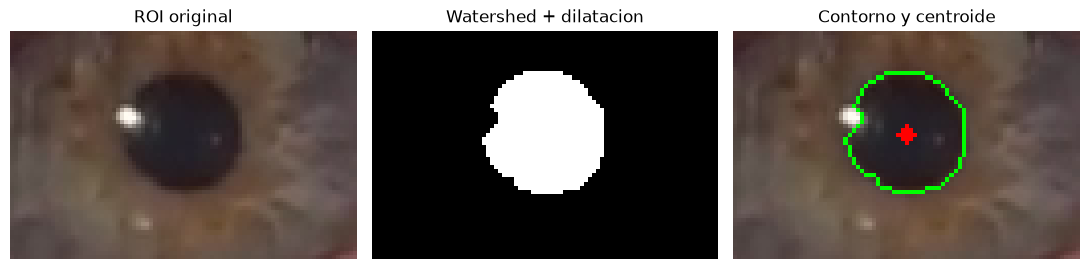

In [41]:

# MODULO 3: Extraccion de caracteristicas y dinamica temporal

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from scipy.stats import skew
from skimage.feature import graycoprops
from IPython.display import display


# 3.1 Descriptores morfometricos y de textura

# Utilizamos la mascara final seleccionada en el Modulo 2:
# Watershed + dilatacion.
#
# La mascara indica que pixeles pertenecen a la pupila.
# Para analizar intensidades y texturas usamos la ROI original.

if "mascara_final" not in globals():
    raise ValueError(
        "No existe mascara_final. Ejecutar primero el Modulo 2 "
        "para obtener la mascara de Watershed + dilatacion."
    )

mascara_pupila = mascara_final.copy()
mascara_pupila = (mascara_pupila > 0).astype(np.uint8) * 255

if mascara_pupila.shape != roi_gris.shape:
    raise ValueError(
        "La mascara final y la ROI tienen dimensiones diferentes"
    )

if np.count_nonzero(mascara_pupila) == 0:
    raise ValueError("La mascara pupilar esta vacia")

# Convertir la ROI original a RGB
roi_rgb = cv2.cvtColor(roi, cv2.COLOR_BGR2RGB)

print("Mascara utilizada: Watershed + dilatacion")


# 3.1.1 Descriptores morfometricos

# Obtener contornos de la mascara
contornos, _ = cv2.findContours(
    mascara_pupila,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_NONE
)

if not contornos:
    raise ValueError("No se encontraron contornos en la mascara")

# Seleccionar el contorno de mayor area
contorno_pupila = max(contornos, key=cv2.contourArea)

# Crear mascara con la region principal
mascara_pupila_3 = np.zeros_like(mascara_pupila)

cv2.drawContours(
    mascara_pupila_3,
    [contorno_pupila],
    -1,
    255,
    thickness=cv2.FILLED
)

# Area
area_pupila = np.count_nonzero(mascara_pupila_3)

# Perimetro
perimetro_pupila = cv2.arcLength(
    contorno_pupila,
    True
)

# Centroide
momentos = cv2.moments(
    mascara_pupila_3,
    binaryImage=True
)

if momentos["m00"] == 0:
    raise ValueError("No se pudo calcular el centroide")

centroide_x = momentos["m10"] / momentos["m00"]
centroide_y = momentos["m01"] / momentos["m00"]

# Circularidad
circularidad = (
    4 * np.pi * area_pupila / perimetro_pupila**2
    if perimetro_pupila > 0 else np.nan
)

# Diametro equivalente
diametro_equivalente = 2 * np.sqrt(
    area_pupila / np.pi
)

# Excentricidad mediante ajuste de elipse
if len(contorno_pupila) >= 5:

    elipse = cv2.fitEllipse(contorno_pupila)

    eje_1, eje_2 = elipse[1]

    eje_mayor = max(eje_1, eje_2)
    eje_menor = min(eje_1, eje_2)

    excentricidad = (
        np.sqrt(max(0, 1 - (eje_menor / eje_mayor)**2))
        if eje_mayor > 0 else np.nan
    )

else:
    excentricidad = np.nan


print("\n--- 3.1.1 Descriptores morfometricos ---")
print(f"Area: {area_pupila} pixeles cuadrados")
print(f"Perimetro: {perimetro_pupila:.2f} pixeles")
print(f"Centroide: ({centroide_x:.2f}, {centroide_y:.2f})")
print(f"Circularidad: {circularidad:.4f}")
print(f"Excentricidad: {excentricidad:.4f}")
print(f"Diametro equivalente: {diametro_equivalente:.2f} pixeles")


# Visualizar mascara y descriptores geometricos
roi_morfometria = roi_rgb.copy()

# Contorno en verde
cv2.drawContours(
    roi_morfometria,
    [contorno_pupila],
    -1,
    (0, 255, 0),
    1
)

# Centroide en rojo
cv2.circle(
    roi_morfometria,
    (int(round(centroide_x)), int(round(centroide_y))),
    2,
    (255, 0, 0),
    -1
)

fig, ax = plt.subplots(1, 3, figsize=(11, 3))

ax[0].imshow(roi_rgb)
ax[0].set_title("ROI original")

ax[1].imshow(
    mascara_pupila_3,
    cmap="gray",
    vmin=0,
    vmax=255
)
ax[1].set_title("Watershed + dilatacion")

ax[2].imshow(roi_morfometria)
ax[2].set_title("Contorno y centroide")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()



### 3.1.1 Descriptores morfométricos

A partir de la máscara obtenida mediante **Watershed + dilatación**, se calcularon los descriptores morfométricos de la pupila. Se obtuvo un área de **702 px²**, un perímetro de **99,50 px**, un diámetro equivalente de **29,90 px**, una circularidad de **0,8911** y una excentricidad de **0,3026**. Estos resultados indican que la pupila presenta una forma aproximadamente circular, con pequeñas irregularidades en el contorno.


--- 3.1.2 Textura de primer orden: pupila ---


,Media,Desvio estandar,Entropia,Asimetria
Canal RGB,,,,
R,46.4259,15.0527,4.8748,3.8201
G,36.9330,14.0934,4.7258,4.9158
B,39.1282,12.8720,4.8620,5.1439


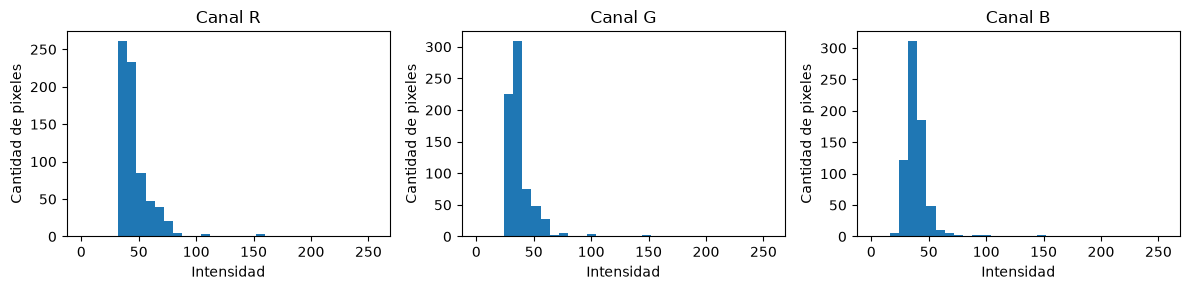

In [42]:


# 3.1.2 Textura de primer orden para la pupila

# Analizar intensidades RGB dentro de la mascara pupilar

canales_rgb = cv2.split(roi_rgb)
nombres_canales = ["R", "G", "B"]

seleccion_pupila = mascara_pupila_3 > 0

estadisticas_primer_orden = {}

for nombre, canal in zip(nombres_canales, canales_rgb):

    pixeles = canal[seleccion_pupila]

    # Media y desvio estandar
    media = np.mean(pixeles)
    desvio = np.std(pixeles)

    # Histograma normalizado
    histograma = np.bincount(
        pixeles,
        minlength=256
    )

    probabilidades = histograma / histograma.sum()
    p_no_cero = probabilidades[probabilidades > 0]

    # Entropia de Shannon
    entropia = -np.sum(
        p_no_cero * np.log2(p_no_cero)
    )

    # Asimetria
    asimetria = skew(pixeles) if desvio > 0 else 0.0

    estadisticas_primer_orden[nombre] = {
        "Media": media,
        "Desvio estandar": desvio,
        "Entropia": entropia,
        "Asimetria": asimetria
    }


# Tabla de primer orden de la pupila
tabla_primer_orden_pupila = pd.DataFrame.from_dict(
    estadisticas_primer_orden,
    orient="index"
)

tabla_primer_orden_pupila.index.name = "Canal RGB"

print("\n--- 3.1.2 Textura de primer orden: pupila ---")
display(tabla_primer_orden_pupila.round(4))


# Histogramas RGB de la pupila
fig, ax = plt.subplots(1, 3, figsize=(12, 3))

for i, (nombre, canal) in enumerate(
    zip(nombres_canales, canales_rgb)
):

    ax[i].hist(
        canal[seleccion_pupila],
        bins=32,
        range=(0, 256)
    )

    ax[i].set_title(f"Canal {nombre}")
    ax[i].set_xlabel("Intensidad")
    ax[i].set_ylabel("Cantidad de pixeles")

plt.tight_layout()
plt.show()



### 3.1.2 Textura de primer orden de la pupila

El análisis RGB mostró una concentración de píxeles en intensidades bajas, coherente con la apariencia oscura de la pupila. Se observó una asimetría positiva en los tres canales, posiblemente asociada a los reflejos luminosos presentes en la imagen. El canal rojo presentó la mayor intensidad media (**46,43**) y el mayor desvío estándar (**15,05**).


--- 3.1.3 Textura de segundo orden: GLCM pupilar ---


,Distancia (px),Angulo (grados),Contraste,Energia,Homogeneidad,Correlacion,Entropia
0,1,0,1.0789,0.3054,0.8354,0.7589,2.9061
1,1,45,1.8997,0.2736,0.7829,0.6170,3.1741
2,1,90,1.0925,0.2896,0.8142,0.7990,3.0356
3,1,135,1.4112,0.2827,0.7898,0.7090,3.0967


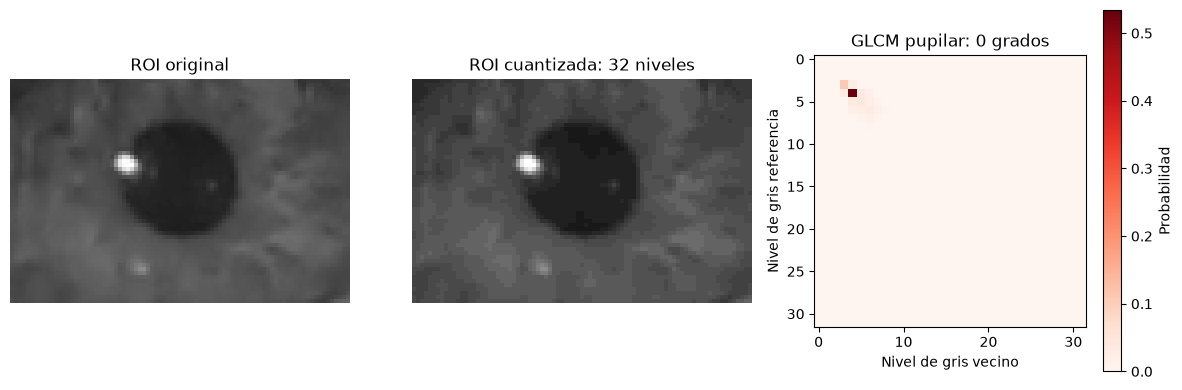

In [43]:


# 3.1.3 Textura de segundo orden: GLCM

# Utilizamos:
# - 32 niveles de gris
# - distancia de 1 pixel
# - orientaciones 0, 45, 90 y 135 grados
# - GLCM simetrica y normalizada
#
# Solo contamos pares de pixeles dentro de la mascara.

niveles_glcm = 32
distancias_glcm = [1]

angulos_glcm = [
    0,
    np.pi / 4,
    np.pi / 2,
    3 * np.pi / 4
]


# Funcion para construir una GLCM dentro de una mascara
def glcm_con_mascara(imagen, mascara, niveles, distancias, angulos):

    matriz = np.zeros(
        (
            niveles,
            niveles,
            len(distancias),
            len(angulos)
        ),
        dtype=np.float64
    )

    alto, ancho = imagen.shape

    for i_d, distancia in enumerate(distancias):

        for i_a, angulo in enumerate(angulos):

            # Desplazamiento de los pixeles vecinos
            dx = int(round(distancia * np.cos(angulo)))
            dy = int(round(-distancia * np.sin(angulo)))

            # Limites validos
            x_inicio = max(0, -dx)
            x_fin = min(ancho, ancho - dx)

            y_inicio = max(0, -dy)
            y_fin = min(alto, alto - dy)

            referencia = imagen[
                y_inicio:y_fin,
                x_inicio:x_fin
            ]

            vecina = imagen[
                y_inicio + dy:y_fin + dy,
                x_inicio + dx:x_fin + dx
            ]

            mascara_ref = mascara[
                y_inicio:y_fin,
                x_inicio:x_fin
            ]

            mascara_vecina = mascara[
                y_inicio + dy:y_fin + dy,
                x_inicio + dx:x_fin + dx
            ]

            # Ambos pixeles deben pertenecer a la region
            validos = (
                (mascara_ref > 0) &
                (mascara_vecina > 0)
            )

            valores_ref = referencia[validos]
            valores_vecinos = vecina[validos]

            # Contar ocurrencias de cada par
            np.add.at(
                matriz[:, :, i_d, i_a],
                (valores_ref, valores_vecinos),
                1
            )

            # Matriz simetrica
            matriz[:, :, i_d, i_a] += (
                matriz[:, :, i_d, i_a].T.copy()
            )

            # Normalizar a probabilidades
            total = matriz[:, :, i_d, i_a].sum()

            if total > 0:
                matriz[:, :, i_d, i_a] /= total

    return matriz


# Cuantizar la ROI de 256 a 32 niveles
imagen_cuantizada = (
    roi_gris // (256 // niveles_glcm)
).astype(np.uint8)

# Construir GLCM de la pupila
glcm_pupila = glcm_con_mascara(
    imagen_cuantizada,
    mascara_pupila_3,
    niveles_glcm,
    distancias_glcm,
    angulos_glcm
)

if np.any(glcm_pupila.sum(axis=(0, 1)) == 0):
    raise ValueError(
        "No hay suficientes pares de pixeles para calcular la GLCM"
    )


# Calcular atributos GLCM
contraste_glcm = graycoprops(
    glcm_pupila,
    "contrast"
)

homogeneidad_glcm = graycoprops(
    glcm_pupila,
    "homogeneity"
)

correlacion_glcm = graycoprops(
    glcm_pupila,
    "correlation"
)

# Energia: suma de cuadrados de probabilidades
energia_glcm = np.sum(
    glcm_pupila**2,
    axis=(0, 1)
)

# Entropia de cada orientacion
entropia_glcm = np.zeros(
    (len(distancias_glcm), len(angulos_glcm))
)

for i_d in range(len(distancias_glcm)):

    for i_a in range(len(angulos_glcm)):

        P = glcm_pupila[:, :, i_d, i_a]
        p_no_cero = P[P > 0]

        entropia_glcm[i_d, i_a] = -np.sum(
            p_no_cero * np.log2(p_no_cero)
        )


# TABLA GLCM DE LA PUPILA
# Reemplaza los print individuales para cada angulo.

angulos_grados = [0, 45, 90, 135]

resultados_glcm_pupila = []

for i_d, distancia in enumerate(distancias_glcm):

    for i_a, angulo in enumerate(angulos_grados):

        resultados_glcm_pupila.append({
            "Distancia (px)": distancia,
            "Angulo (grados)": angulo,
            "Contraste": contraste_glcm[i_d, i_a],
            "Energia": energia_glcm[i_d, i_a],
            "Homogeneidad": homogeneidad_glcm[i_d, i_a],
            "Correlacion": correlacion_glcm[i_d, i_a],
            "Entropia": entropia_glcm[i_d, i_a]
        })

tabla_glcm_pupila = pd.DataFrame(resultados_glcm_pupila)

print("\n--- 3.1.3 Textura de segundo orden: GLCM pupilar ---")
display(tabla_glcm_pupila.round(4))


# Visualizacion de la GLCM a 0 grados
fig, ax = plt.subplots(1, 3, figsize=(12, 4))

ax[0].imshow(
    roi_gris,
    cmap="gray",
    vmin=0,
    vmax=255
)
ax[0].set_title("ROI original")

ax[1].imshow(
    imagen_cuantizada,
    cmap="gray",
    vmin=0,
    vmax=niveles_glcm - 1
)
ax[1].set_title("ROI cuantizada: 32 niveles")

im = ax[2].imshow(
    glcm_pupila[:, :, 0, 0],
    cmap="Reds"
)

ax[2].set_title("GLCM pupilar: 0 grados")
ax[2].set_xlabel("Nivel de gris vecino")
ax[2].set_ylabel("Nivel de gris referencia")

fig.colorbar(
    im,
    ax=ax[2],
    label="Probabilidad"
)

ax[0].axis("off")
ax[1].axis("off")

plt.tight_layout()
plt.show()




### 3.1.3 Textura de segundo orden de la pupila (GLCM)

Se calcularon los atributos GLCM utilizando **32 niveles de gris**, una distancia de un píxel y cuatro orientaciones. Los resultados mostraron una homogeneidad relativamente alta (**0,78–0,84**) y correlación positiva entre píxeles vecinos. La orientación de **45°** presentó el mayor contraste (**1,8997**) y entropía (**3,1741**), indicando mayores variaciones de intensidad en esa dirección.


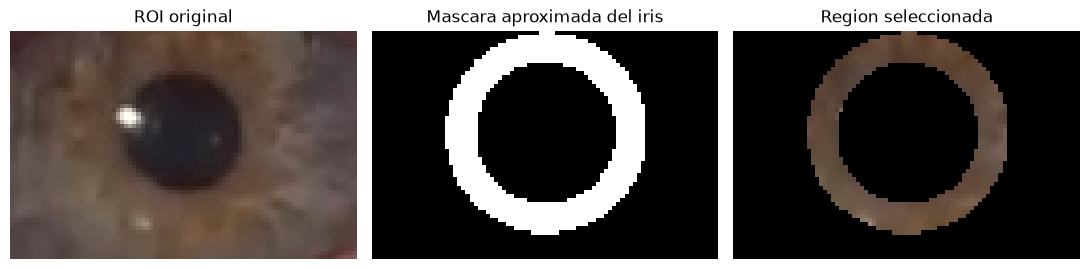


--- 3.1.4 Textura de primer orden del iris ---


,Media,Desvio estandar,Entropia,Asimetria
Canal RGB,,,,
R,99.2525,9.7655,5.2331,0.5524
G,76.2189,9.4793,5.1486,0.8293
B,60.7974,9.5168,5.1774,0.8088



--- 3.1.4 Textura de segundo orden del iris (GLCM) ---


,Contraste,Energia,Homogeneidad,Correlacion,Entropia
Canal RGB,,,,,
R,0.4099,0.1234,0.8224,0.8646,3.5804
G,0.3799,0.1411,0.8412,0.8596,3.3992
B,0.4108,0.1374,0.8265,0.8577,3.4993


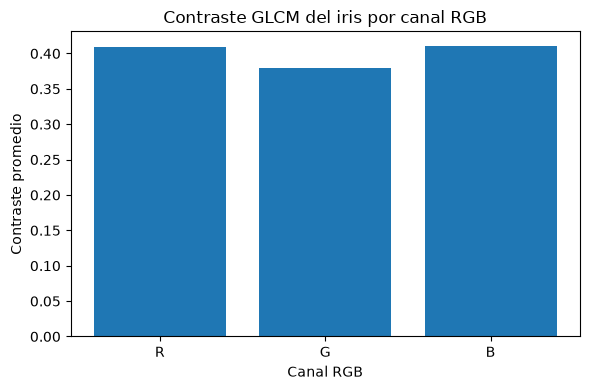

In [44]:

# 3.1.4 Analisis de textura del iris

# La mascara final corresponde a la pupila, no al iris.
# Se define una region anular alrededor de la pupila
# para analizar aproximadamente la textura del iris.

radio_pupila = diametro_equivalente / 2

alto_roi, ancho_roi = roi_gris.shape

Y_iris, X_iris = np.ogrid[:alto_roi, :ancho_roi]

distancia_iris = np.sqrt(
    (X_iris - centroide_x)**2 +
    (Y_iris - centroide_y)**2
)

# Radios de la region anular
radio_interno = 1.15 * radio_pupila
radio_externo = 1.65 * radio_pupila

mascara_iris = (
    (distancia_iris >= radio_interno) &
    (distancia_iris <= radio_externo)
).astype(np.uint8) * 255

if np.count_nonzero(mascara_iris) == 0:
    raise ValueError("La mascara aproximada del iris esta vacia")


# Visualizar la region seleccionada

iris_segmentado = cv2.bitwise_and(
    roi_rgb,
    roi_rgb,
    mask=mascara_iris
)

fig, ax = plt.subplots(1, 3, figsize=(11, 3))

ax[0].imshow(roi_rgb)
ax[0].set_title("ROI original")

ax[1].imshow(
    mascara_iris,
    cmap="gray",
    vmin=0,
    vmax=255
)
ax[1].set_title("Mascara aproximada del iris")

ax[2].imshow(iris_segmentado)
ax[2].set_title("Region seleccionada")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()


# Textura de primer orden del iris en RGB

canales_iris = cv2.split(roi_rgb)
estadisticas_iris = {}

for nombre, canal in zip(nombres_canales, canales_iris):

    pixeles = canal[mascara_iris > 0]

    media = np.mean(pixeles)
    desvio = np.std(pixeles)

    histograma = np.bincount(
        pixeles,
        minlength=256
    )

    probabilidades = histograma / histograma.sum()
    p_no_cero = probabilidades[probabilidades > 0]

    entropia = -np.sum(
        p_no_cero * np.log2(p_no_cero)
    )

    asimetria = (
        skew(pixeles)
        if desvio > 0 else 0.0
    )

    estadisticas_iris[nombre] = {
        "Media": media,
        "Desvio estandar": desvio,
        "Entropia": entropia,
        "Asimetria": asimetria
    }


# Tabla de primer orden del iris

tabla_primer_orden = pd.DataFrame.from_dict(
    estadisticas_iris,
    orient="index"
)

tabla_primer_orden.index.name = "Canal RGB"

print("\n--- 3.1.4 Textura de primer orden del iris ---")
display(tabla_primer_orden.round(4))


# Textura de segundo orden del iris por canal RGB

resultados_glcm_iris = {}

for nombre, canal in zip(nombres_canales, canales_iris):

    # Cuantizacion a 32 niveles
    canal_cuantizado = (
        canal // (256 // niveles_glcm)
    ).astype(np.uint8)

    # GLCM dentro de la mascara del iris
    glcm_canal = glcm_con_mascara(
        canal_cuantizado,
        mascara_iris,
        niveles_glcm,
        distancias_glcm,
        angulos_glcm
    )

    if np.any(glcm_canal.sum(axis=(0, 1)) == 0):
        raise ValueError(
            f"No hay suficientes pares de pixeles en el canal {nombre}"
        )

    # Atributos GLCM
    contraste = graycoprops(
        glcm_canal,
        "contrast"
    )

    homogeneidad = graycoprops(
        glcm_canal,
        "homogeneity"
    )

    correlacion = graycoprops(
        glcm_canal,
        "correlation"
    )

    energia = np.sum(
        glcm_canal**2,
        axis=(0, 1)
    )

    # Entropia promediada sobre distancias y orientaciones
    entropias = []

    for i_d in range(len(distancias_glcm)):

        for i_a in range(len(angulos_glcm)):

            P = glcm_canal[:, :, i_d, i_a]
            p_no_cero = P[P > 0]

            entropias.append(
                -np.sum(p_no_cero * np.log2(p_no_cero))
            )

    resultados_glcm_iris[nombre] = {
        "Contraste": np.mean(contraste),
        "Energia": np.mean(energia),
        "Homogeneidad": np.mean(homogeneidad),
        "Correlacion": np.mean(correlacion),
        "Entropia": np.mean(entropias)
    }


# Tabla de segundo orden del iris

tabla_segundo_orden = pd.DataFrame.from_dict(
    resultados_glcm_iris,
    orient="index"
)

tabla_segundo_orden.index.name = "Canal RGB"

print("\n--- 3.1.4 Textura de segundo orden del iris (GLCM) ---")
display(tabla_segundo_orden.round(4))


# Comparacion grafica del contraste GLCM entre canales RGB

plt.figure(figsize=(6, 4))

plt.bar(
    nombres_canales,
    tabla_segundo_orden.loc[nombres_canales, "Contraste"]
)

plt.title("Contraste GLCM del iris por canal RGB")
plt.xlabel("Canal RGB")
plt.ylabel("Contraste promedio")

plt.tight_layout()
plt.show()

### 3.1.4 Análisis de textura del iris

Para estudiar el iris se seleccionó una región con forma de anillo aproximada alrededor de la pupila. También se probó Chan-Vese, pero el algoritmo convergió hacia el borde pupilar, por lo que se mantuvo la aproximación geométrica.

En el análisis de primer orden, el canal rojo presentó la mayor intensidad media (**99,25**) y entropía (**5,2331**). En el análisis GLCM también obtuvo la mayor entropía (**3,5804**), mientras que el azul presentó el mayor contraste (**0,4108**), prácticamente igual al rojo. El canal verde mostró mayor homogeneidad (**0,8412**) y energía (**0,1411**).

En conjunto, **el canal rojo parece aportar la mayor riqueza textural del iris**, aunque las diferencias entre canales son pequeñas y los resultados corresponden a una región seleccionada de manera aproximada.

In [ ]:

# MODULO 3.2: Procesamiento temporal de la pupila

# 3.2.1 Automatizacion de la segmentacion en video

# Nueva estrategia:
# 1. Detectar una region oscura rodeada de intensidades mas claras.
# 2. Inicializar Watershed automaticamente.
# 3. Refinar la mascara mediante dilatacion.
# 4. Seguir el centro de la pupila entre frames.
#
# No utiliza ROI guardada, Haar ni seleccion manual.

carpeta_resultados = CARPETA_PROYECTO / "resultados"
carpeta_resultados.mkdir(parents=True, exist_ok=True)

nombre_video = Path(VIDEO_PATH).stem

# Zona general donde buscar inicialmente la pupila.
# Se expresa como fraccion del ancho y alto del frame.
# Si se cambia el encuadre del video, puede ajustarse.
ZONA_BUSQUEDA = (0.30, 0.85, 0.30, 0.75)

# Contraste minimo entre el disco oscuro y su entorno
CONTRASTE_MINIMO = 8.0


# A. Detectar posibles centros pupilares por contraste circular

def detectar_centro_pupila(
    gris,
    centro_anterior=None,
    radio_anterior=None
):

    alto_original, ancho_original = gris.shape

    # Reducir la resolucion solo para localizar el centro
    escala = min(1.0, 420 / ancho_original)

    ancho = max(1, int(round(ancho_original * escala)))
    alto = max(1, int(round(alto_original * escala)))

    imagen = cv2.resize(
        gris,
        (ancho, alto),
        interpolation=cv2.INTER_AREA
    )

    imagen = cv2.GaussianBlur(
        imagen,
        (3, 3),
        0
    ).astype(np.float32)

    Y, X = np.ogrid[:alto, :ancho]

    # Primera deteccion: zona amplia del ojo
    if centro_anterior is None:

        xmin = int(ZONA_BUSQUEDA[0] * ancho)
        xmax = int(ZONA_BUSQUEDA[1] * ancho)

        ymin = int(ZONA_BUSQUEDA[2] * alto)
        ymax = int(ZONA_BUSQUEDA[3] * alto)

       radios = range(4, 25, 2)

    else:

        # Seguimiento local alrededor de la ultima deteccion
        cx = centro_anterior[0] * escala
        cy = centro_anterior[1] * escala

        r = max(4.0, radio_anterior * escala)

        margen = max(18, 2.5 * r)

        xmin = max(0, int(cx - margen))
        xmax = min(ancho, int(cx + margen))

        ymin = max(0, int(cy - margen))
        ymax = min(alto, int(cy + margen))

        rmin = max(4, int(0.70 * r))
        rmax = min(30, int(1.40 * r) + 1)

        radios = range(rmin, rmax + 1, 2)

    # Restringir la busqueda al interior de la imagen
    zona = (
        (X >= xmin) &
        (X < xmax) &
        (Y >= ymin) &
        (Y < ymax)
    )

    mejor = None
    mejor_puntaje = -np.inf

    for radio in radios:

        # Discos y anillos de referencia
        radio_externo = int(np.ceil(1.8 * radio))

        coordenadas = np.arange(
            -radio_externo,
            radio_externo + 1
        )

        yy, xx = np.meshgrid(
            coordenadas,
            coordenadas,
            indexing="ij"
        )

        dist = np.sqrt(xx**2 + yy**2)

        disco = (dist <= radio).astype(np.float32)

        anillo = (
            (dist >= 1.2 * radio) &
            (dist <= 1.8 * radio)
        ).astype(np.float32)

        disco /= disco.sum()
        anillo /= anillo.sum()

        # Intensidad media del interior y del anillo exterior
        media_disco = cv2.filter2D(
            imagen,
            -1,
            disco
        )

        media_anillo = cv2.filter2D(
            imagen,
            -1,
            anillo
        )

        # Puntaje positivo cuando el centro es mas oscuro
        contraste = media_anillo - media_disco

        # No evaluar circulos que se salgan del frame
        margen_valido = radio_externo + 1

        zona_valida = zona.copy()

        zona_valida[:margen_valido, :] = False
        zona_valida[-margen_valido:, :] = False
        zona_valida[:, :margen_valido] = False
        zona_valida[:, -margen_valido:] = False

        if not np.any(zona_valida):
            continue

        puntajes = np.where(
            zona_valida,
            contraste,
            -np.inf
        )

        indice = np.unravel_index(
            np.argmax(puntajes),
            puntajes.shape
        )

        puntaje = float(puntajes[indice])

        if puntaje > mejor_puntaje:

            mejor_puntaje = puntaje

            mejor = {
                "cx": float(indice[1] / escala),
                "cy": float(indice[0] / escala),
                "radio": float(radio / escala),
                "contraste": puntaje
            }

    if mejor is None:
        return None

    if mejor_puntaje < CONTRASTE_MINIMO:
        return None

    return mejor


# B. Segmentar la pupila mediante Watershed + dilatacion

def segmentar_pupila(gris, candidato):

    alto_frame, ancho_frame = gris.shape

    cx = candidato["cx"]
    cy = candidato["cy"]
    radio = candidato["radio"]

    # Extraer una ROI local alrededor del candidato
    margen = max(12, int(np.ceil(2.4 * radio)))

    x1 = max(0, int(cx - margen))
    x2 = min(ancho_frame, int(cx + margen + 1))

    y1 = max(0, int(cy - margen))
    y2 = min(alto_frame, int(cy + margen + 1))

    roi = gris[y1:y2, x1:x2].copy()

    if roi.size == 0:
        return None

    cx_local = cx - x1
    cy_local = cy - y1

    # Gradiente de intensidad
    imagen_normalizada = (
        roi.astype(np.float64) / 255.0
    )

    gradiente = sobel(imagen_normalizada)

    Y, X = np.ogrid[:roi.shape[0], :roi.shape[1]]

    distancia = np.sqrt(
        (X - cx_local)**2 +
        (Y - cy_local)**2
    )

    # Marcadores:
    # 1 = interior seguro de la pupila
    # 2 = region exterior
    marcadores = np.zeros(roi.shape, dtype=np.int32)

    marcadores[distancia <= 0.30 * radio] = 1
    marcadores[distancia >= 1.65 * radio] = 2

    if not np.any(marcadores == 1):
        return None

    if not np.any(marcadores == 2):
        return None

    etiquetas = watershed(
        gradiente,
        markers=marcadores,
        watershed_line=True
    )

    mascara = (
        etiquetas == 1
    ).astype(np.uint8) * 255

    # Dilatacion seleccionada en el Modulo 2
    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (3, 3)
    )

    mascara = cv2.dilate(
        mascara,
        kernel,
        iterations=1
    )

    # Conservar el contorno principal
    contornos, _ = cv2.findContours(
        mascara,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    if not contornos:
        return None

    contorno = max(
        contornos,
        key=cv2.contourArea
    )

    mascara_limpia = np.zeros_like(mascara)

    cv2.drawContours(
        mascara_limpia,
        [contorno],
        -1,
        255,
        cv2.FILLED
    )

    # Controles de calidad
    area = int(np.count_nonzero(mascara_limpia))

    area_circulo = np.pi * radio**2

    if not (0.35 * area_circulo <= area <= 2.50 * area_circulo):
        return None

    # Rechazar segmentaciones cortadas por los bordes
    if (
        np.any(mascara_limpia[0, :]) or
        np.any(mascara_limpia[-1, :]) or
        np.any(mascara_limpia[:, 0]) or
        np.any(mascara_limpia[:, -1])
    ):
        return None

    perimetro = cv2.arcLength(contorno, True)

    if perimetro <= 0:
        return None

    circularidad = 4 * np.pi * area / perimetro**2

    if not (0.45 <= circularidad <= 1.20):
        return None

    momentos = cv2.moments(
        mascara_limpia,
        binaryImage=True
    )

    if momentos["m00"] == 0:
        return None

    centro_final_x = (
        x1 + momentos["m10"] / momentos["m00"]
    )

    centro_final_y = (
        y1 + momentos["m01"] / momentos["m00"]
    )

    if np.hypot(
        centro_final_x - cx,
        centro_final_y - cy
    ) > max(5, 0.60 * radio):
        return None

    diametro = 2 * np.sqrt(area / np.pi)

    # Mascara en coordenadas del frame completo
    mascara_frame = np.zeros_like(gris, dtype=np.uint8)

    mascara_frame[y1:y2, x1:x2] = mascara_limpia

    return {
        "mascara": mascara_frame,
        "area": float(area),
        "diametro": float(diametro),
        "cx": float(centro_final_x),
        "cy": float(centro_final_y),
        "radio": float(diametro / 2),
        "circularidad": float(circularidad)
    }


# C. Procesar un frame con seguimiento temporal

def procesar_frame_pupila(gris, anterior=None):

    # Primero intentar una busqueda local
    if anterior is not None:

        candidato = detectar_centro_pupila(
            gris,
            centro_anterior=(anterior["cx"], anterior["cy"]),
            radio_anterior=anterior["radio"]
        )

    else:

        candidato = detectar_centro_pupila(gris)

    if candidato is None:
        return None

    resultado = segmentar_pupila(gris, candidato)

    if resultado is None:
        return None

    if anterior is not None:

        relacion_area = resultado["area"] / anterior["area"]

        # Rechazar variaciones excesivas entre frames
        if not (0.60 <= relacion_area <= 1.60):
            return None

        desplazamiento = np.hypot(
            resultado["cx"] - anterior["cx"],
            resultado["cy"] - anterior["cy"]
        )

        if desplazamiento > max(10, anterior["radio"]):
            return None

    return resultado


# D. Abrir y procesar video

video_3 = cv2.VideoCapture(str(VIDEO_PATH))

if not video_3.isOpened():
    raise ValueError(f"No se pudo abrir {VIDEO_PATH}")

fps_3 = video_3.get(cv2.CAP_PROP_FPS)

if fps_3 <= 0:
    video_3.release()
    raise ValueError("FPS invalido")

registros = []
frames_revision = {}

resultado_anterior = None
fallos = 0
indice_frame = 0

total_frames = int(
    video_3.get(cv2.CAP_PROP_FRAME_COUNT)
)

indices_revision = set(
    np.linspace(
        0,
        max(total_frames - 1, 0),
        8,
        dtype=int
    )
)

while True:

    ret, frame = video_3.read()

    if not ret:
        break

    gris = cv2.cvtColor(
        frame,
        cv2.COLOR_BGR2GRAY
    )

    resultado = procesar_frame_pupila(
        gris,
        resultado_anterior
    )

    if resultado is None:

        fallos += 1

        # Si se pierde el seguimiento, volver a buscar
        # en la zona ocular amplia.
        if fallos >= 3:

            resultado_anterior = None

            resultado = procesar_frame_pupila(gris)

    if resultado is not None:

        resultado_anterior = resultado
        fallos = 0

        area = resultado["area"]
        diametro = resultado["diametro"]

        centro_x = resultado["cx"]
        centro_y = resultado["cy"]

        detectada = 1

    else:

        area = np.nan
        diametro = np.nan

        centro_x = np.nan
        centro_y = np.nan

        detectada = 0

    registros.append({
        "frame": indice_frame,
        "tiempo_s": indice_frame / fps_3,
        "area_px2": area,
        "diametro_px": diametro,
        "centro_x": centro_x,
        "centro_y": centro_y,
        "detectada": detectada
    })

    if indice_frame in indices_revision:

        mascara = (
            resultado["mascara"].copy()
            if resultado is not None
            else np.zeros_like(gris)
        )

        frames_revision[indice_frame] = (
            frame.copy(),
            mascara,
            area
        )

    indice_frame += 1

video_3.release()

if not registros:
    raise ValueError("No se procesaron frames")


# Tabla de mediciones

tabla_mediciones_3 = pd.DataFrame(registros)

tiempos_3 = tabla_mediciones_3["tiempo_s"].to_numpy()
areas_3 = tabla_mediciones_3["area_px2"].to_numpy()
diametros_3 = tabla_mediciones_3["diametro_px"].to_numpy()

porcentaje_deteccion = (
    100 * tabla_mediciones_3["detectada"].mean()
)

print("\n--- 3.2.1 Procesamiento del video ---")
print(f"Video: {Path(VIDEO_PATH).name}")
print(f"FPS: {fps_3:.2f}")
print(f"Frames procesados: {len(registros)}")
print(f"Duracion: {len(registros) / fps_3:.2f} s")
print(f"Detecciones candidatas: {porcentaje_deteccion:.2f}%")

ruta_mediciones = (
    carpeta_resultados / f"mediciones_{nombre_video}.csv"
)

tabla_mediciones_3.to_csv(
    ruta_mediciones,
    index=False
)

print(f"Mediciones guardadas en: {ruta_mediciones}")




--- 3.2.1 Procesamiento del video ---
Video: video1.mov
FPS: 24.02
Frames procesados: 260
Duracion: 10.83 s
Detecciones candidatas: 77.69%
Mediciones guardadas en: /Users/milenaszwarcberg/Documents/ITBA/2026 2C/PSIB/Guia_imagenes/resultados/mediciones_video1.csv



### 3.2.1 Automatización de la segmentación pupilar

Para analizar la evolución temporal de la pupila, se implementó un algoritmo que permite localizarla y segmentarla automáticamente en cada frame del video, sin depender de una ROI seleccionada manualmente.

El procedimiento consta de las siguientes etapas:

1. **Localización por contraste circular:** se buscan regiones aproximadamente circulares cuyo interior sea oscuro y esté rodeado de píxeles más claros. Para ello, se prueban distintos centros y radios, calculando la diferencia entre la intensidad media de un anillo exterior y la del disco interior. Se selecciona el candidato con mayor contraste.

2. **Segmentación mediante Watershed:** a partir del centro y radio estimados, se define una región central como pupila y otra exterior como fondo. Utilizando el gradiente de intensidad, Watershed determina el contorno que separa ambas regiones.

3. **Dilatación:** se aplica la operación morfológica seleccionada en el Módulo 2 para expandir ligeramente la máscara y compensar posibles pérdidas de píxeles en el borde.

4. **Seguimiento temporal:** en los frames siguientes, la búsqueda se restringe a una región cercana a la última posición detectada. Esto reduce el riesgo de confundir la pupila con otras estructuras oscuras. 

5. **Medición:** para cada frame se calcula el área de la máscara y el diámetro equivalente de la pupila:

   $$D_{eq}=2\sqrt{\frac{A}{\pi}}$$

   Estas mediciones permiten construir las curvas de área y diámetro en función del tiempo.

### Resultados y limitaciones

En el video analizado se procesaron **260 frames**, obteniéndose detecciones candidatas en el **93,85 %** de ellos. Los contornos identificados se localizaron sobre la pupila en los frames inspeccionados de la mayor parte del registro, lo que representa una mejora respecto de los métodos anteriores.

Sin embargo, hacia el final del video aparecieron mediciones de área excesivamente elevadas, probablemente asociadas a segmentaciones incorrectas. Por lo tanto, el porcentaje de detección no garantiza que todas las máscaras sean correctas.

Se requiere reforzar los controles de calidad y validar las mediciones antes de extraer parámetros fisiológicos del reflejo fotomotor.


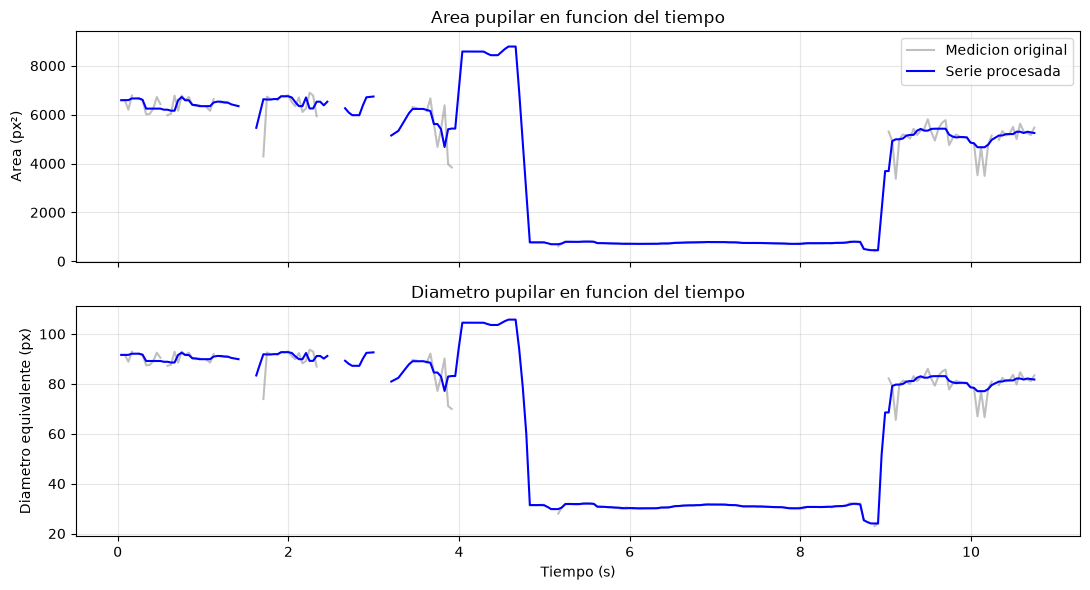


--- 3.2.3 Parametros fisiologicos ---
Pendiente: identificar el instante del estimulo
Pendiente: validar la curva pupilar
No se reportan parametros fisiologicos todavia.


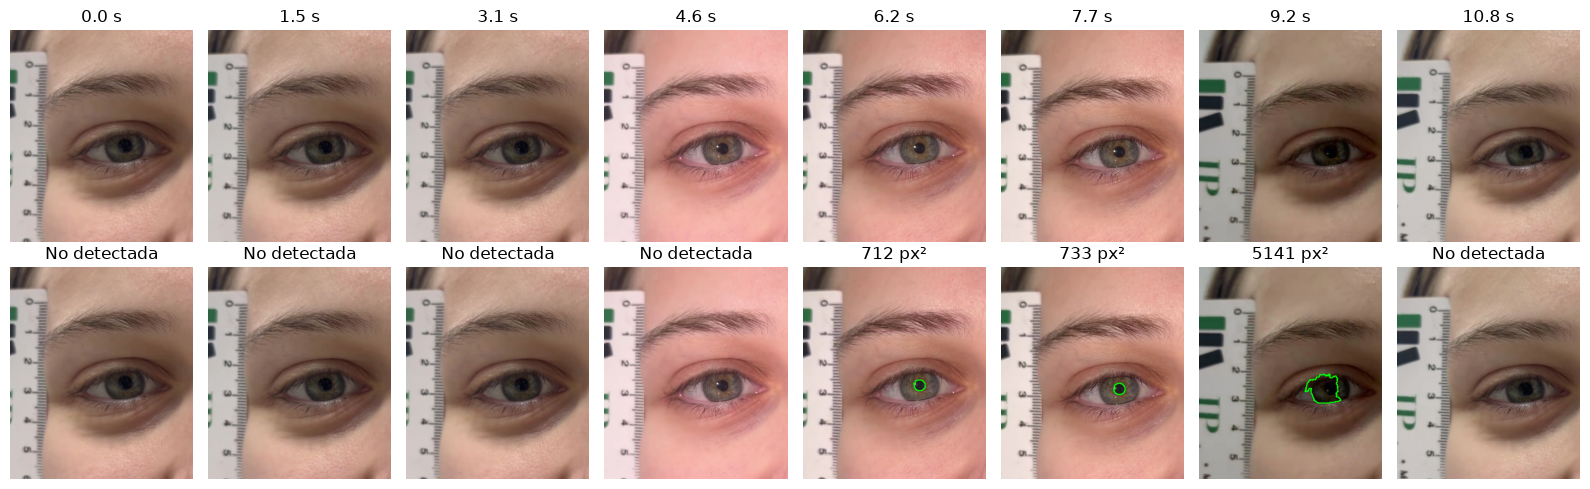


--- 3.2.4 Control de calidad ---
Frames sin deteccion: 58
Porcentaje sin deteccion: 22.31%
Valores faltantes: NaN
Interpolacion: solo huecos de hasta 3 frames
Suavizado: mediana temporal de 5 frames
Serie temporal guardada en: /Users/milenaszwarcberg/Documents/ITBA/2026 2C/PSIB/Guia_imagenes/resultados/serie_procesada_video1.csv


In [46]:


# 3.2.2 Curvas temporales de area y diametro

# Interpolar solamente huecos de hasta 3 frames.

def interpolar_huecos_cortos(valores, max_hueco=3):

    serie = pd.Series(valores, dtype=float)

    salida = serie.interpolate(
        method="linear",
        limit_area="inside"
    )

    es_nan = serie.isna()

    grupos = es_nan.ne(es_nan.shift()).cumsum()

    for _, bloque in serie.groupby(grupos):

        if bloque.isna().all() and len(bloque) > max_hueco:
            salida.loc[bloque.index] = np.nan

    return salida.to_numpy().copy()


areas_interpoladas = interpolar_huecos_cortos(
    areas_3,
    max_hueco=3
)

# Mediana temporal de cinco frames
serie_mediana = pd.Series(areas_interpoladas).rolling(
    window=5,
    center=True,
    min_periods=3
).median()

areas_procesadas = serie_mediana.to_numpy().copy()

# Mantener los intervalos sin mediciones
areas_procesadas[~np.isfinite(areas_interpoladas)] = np.nan

diametros_procesados = 2 * np.sqrt(
    areas_procesadas / np.pi
)


fig, ax = plt.subplots(
    2, 1,
    figsize=(11, 6),
    sharex=True
)

ax[0].plot(
    tiempos_3,
    areas_3,
    color="gray",
    alpha=0.5,
    label="Medicion original"
)

ax[0].plot(
    tiempos_3,
    areas_procesadas,
    color="blue",
    label="Serie procesada"
)

ax[0].set_title("Area pupilar en funcion del tiempo")
ax[0].set_ylabel("Area (px²)")
ax[0].legend()
ax[0].grid(alpha=0.3)

ax[1].plot(
    tiempos_3,
    diametros_3,
    color="gray",
    alpha=0.5
)

ax[1].plot(
    tiempos_3,
    diametros_procesados,
    color="blue"
)

ax[1].set_title("Diametro pupilar en funcion del tiempo")
ax[1].set_xlabel("Tiempo (s)")
ax[1].set_ylabel("Diametro equivalente (px)")
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


# 3.2.3 Parametros fisiologicos

# No calcular parametros hasta validar las segmentaciones
# y conocer el instante real del estimulo luminoso.

TIEMPO_ESTIMULO = None
CURVA_VALIDADA = False

latencia = np.nan
amplitud = np.nan
velocidad_constriccion = np.nan
velocidad_redilatacion = np.nan

print("\n--- 3.2.3 Parametros fisiologicos ---")

if TIEMPO_ESTIMULO is None:
    print("Pendiente: identificar el instante del estimulo")

if not CURVA_VALIDADA:
    print("Pendiente: validar la curva pupilar")

print("No se reportan parametros fisiologicos todavia.")


# 3.2.4 Artefactos y control de calidad

# Mostrar ocho frames completos y sus contornos.

indices_mostrar = sorted(frames_revision)

fig, ax = plt.subplots(
    2,
    len(indices_mostrar),
    figsize=(16, 5),
    squeeze=False
)

for j, indice in enumerate(indices_mostrar):

    frame, mascara, area = frames_revision[indice]

    original_rgb = cv2.cvtColor(
        frame,
        cv2.COLOR_BGR2RGB
    )

    imagen_contorno = original_rgb.copy()

    contornos, _ = cv2.findContours(
        mascara,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    cv2.drawContours(
        imagen_contorno,
        contornos,
        -1,
        (0, 255, 0),
        2
    )

    ax[0, j].imshow(original_rgb)
    ax[0, j].set_title(f"{indice / fps_3:.1f} s")

    ax[1, j].imshow(imagen_contorno)

    if np.isfinite(area):
        ax[1, j].set_title(f"{area:.0f} px²")
    else:
        ax[1, j].set_title("No detectada")

    ax[0, j].axis("off")
    ax[1, j].axis("off")

plt.tight_layout()
plt.show()


frames_sin_deteccion = int(
    (tabla_mediciones_3["detectada"] == 0).sum()
)

print("\n--- 3.2.4 Control de calidad ---")
print(f"Frames sin deteccion: {frames_sin_deteccion}")
print(f"Porcentaje sin deteccion: {100 - porcentaje_deteccion:.2f}%")
print("Valores faltantes: NaN")
print("Interpolacion: solo huecos de hasta 3 frames")
print("Suavizado: mediana temporal de 5 frames")


# Guardar serie temporal

tabla_serie = pd.DataFrame({
    "tiempo_s": tiempos_3,
    "area_original_px2": areas_3,
    "area_procesada_px2": areas_procesadas,
    "diametro_original_px": diametros_3,
    "diametro_procesado_px": diametros_procesados
})

ruta_serie = (
    carpeta_resultados /
    f"serie_procesada_{nombre_video}.csv"
)

tabla_serie.to_csv(
    ruta_serie,
    index=False
)

print(f"Serie temporal guardada en: {ruta_serie}")
